# Notebook 04 (v3): Models, Evaluation, Tuning, Stacking and Hierarchical models
**AID 427 Project Phase 1: MultiCaRe-Fusion**

 Inputs come from Notebooks 02 and 03 (`DataSet/outputs/features` and `outputs/results`).

| Part | Content |
|---|---|
| 1 | Feature sets (all features, LDA, PCA, Elastic Net, Genetic Algorithm) |
| 2 | Models: Logistic Regression, Linear SVM, RBF-SVM, kNN, Random Forest, XGBoost, MLP |
| 3 | 80/20 split evaluation **and** grouped k-fold cross-validation (average accuracy) |
| 4 | Best model: accuracy, error rate, precision, recall, F-measure, ROC-AUC, confusion matrix, per-class results |
| 5 | Over/under-fitting analysis (train vs CV vs test, learning curve) |
| 6 | Modality ablation: image-only vs text-only vs tabular vs fusion |
| 7 | Comparison table with related work |
| 9 | Tuning (regularisation, class weights) and a voting ensemble |
| 10 | Sparse TF-IDF text models (full 3000 columns instead of SVD-200) |
| 11 | **Late fusion / stacking** (one model per modality + a meta-model) |
| 12 | **Hierarchical model** (image type first, then subtype) |
| 13 | **Error analysis** with the misclassified images |
| 14 | Final comparison of everything |

In [1]:
import os, json, time, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.special import softmax
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.linear_model import SGDClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)
try:
    from xgboost import XGBClassifier; HAS_XGB = True
except Exception: HAS_XGB = False
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="notebook")

# ---------------- configuration ----------------
SEED = 42
TARGET = "subtype"             # same as Notebook 03: "subtype" (27 classes) or "type" (7 classes)
FAST = False                   # True = only CV folds 1-2 and fewer models (quick test run)
FULL_GRID = True              # True = also run RandomForest and XGBoost in the Section 3 grid (adds about 40+ min)
CV_FOLDS = [1, 2] if FAST else [1, 2, 3, 4]
np.random.seed(SEED)
DATA_DIR = next(p for p in ["../DataSet", "DataSet", "."] if os.path.exists(os.path.join(p, "outputs", "features", "X_fused_std.npy")))
FEAT, FIG, RES = [os.path.join(DATA_DIR, "outputs", d) for d in ("features", "figures", "results")]
for d in (FIG, RES): os.makedirs(d, exist_ok=True)
def savefig(name): plt.tight_layout(); plt.savefig(os.path.join(FIG, name), dpi=150, bbox_inches="tight"); plt.show()
print("XGBoost available:", HAS_XGB, "(pip install xgboost to enable)")

XGBoost available: True (pip install xgboost to enable)


## 1. Load data and build the feature sets

In [2]:
idx = pd.read_csv(os.path.join(FEAT, "index.csv")); classes = json.load(open(os.path.join(FEAT, "classes.json")))
y_type, y_sub = np.load(os.path.join(FEAT, "y_type.npy")), np.load(os.path.join(FEAT, "y_subtype.npy"))
y = y_sub if TARGET == "subtype" else y_type; class_names = np.array(classes["image_subtype" if TARGET == "subtype" else "image_type"]); K = len(class_names)
Xs = np.load(os.path.join(FEAT, "X_fused_std.npy")); meta = json.load(open(os.path.join(FEAT, "fused_feature_names.json")))
names, block = np.array(meta["names"]), np.array(meta["block"])
w = np.ones(Xs.shape[1], dtype=np.float32)
for b in np.unique(block): w[block == b] = 1 / np.sqrt((block == b).sum())
Xw = Xs * w
SEL = json.load(open(os.path.join(RES, "selected_features.json")))
train_mask, test_mask = (idx.split == "train").values, (idx.split == "test").values
tr_all, te = np.where(train_mask)[0], np.where(test_mask)[0]; fold = idx.fold.values
print("fused:", Xs.shape, "| train", len(tr_all), "| test", len(te), "| classes", K, "| CV folds:", CV_FOLDS)

FSETS = {"All features": None, "LDA": "lda", "PCA-100": "pca", "ElasticNet-100": SEL["Embedded ElasticNet"], "GA-selected": SEL["Genetic Algorithm"]}
print({k: (Xs.shape[1] if v is None else (len(v) if isinstance(v, list) else v)) for k, v in FSETS.items()})
_cache = {}
def build(fs, tr, ev, key):
    '''Returns (train_features, eval_features). PCA/LDA/scaler are fitted on `tr` only (also inside every CV fold).'''
    if (fs, key) in _cache: return _cache[(fs, key)]
    spec = FSETS[fs]
    if spec is None: A, B = Xs[tr], Xs[ev]
    elif isinstance(spec, list): c = np.array(spec); A, B = Xs[tr][:, c], Xs[ev][:, c]
    elif spec == "pca": p = PCA(100, random_state=SEED).fit(Xw[tr]); A, B = p.transform(Xw[tr]), p.transform(Xw[ev])
    else:
        p = PCA(min(200, Xw.shape[1]), random_state=SEED).fit(Xw[tr]); l = LinearDiscriminantAnalysis(n_components=min(K - 1, 26)).fit(p.transform(Xw[tr]), y[tr])
        A, B = l.transform(p.transform(Xw[tr])), l.transform(p.transform(Xw[ev]))
    sc = StandardScaler().fit(A); out = (sc.transform(A).astype(np.float32), sc.transform(B).astype(np.float32))
    if len(_cache) > 12: _cache.clear()
    _cache[(fs, key)] = out; return out

fused: (21988, 5878) | train 17673 | test 4315 | classes 27 | CV folds: [1, 2, 3, 4]
{'All features': 5878, 'LDA': 'lda', 'PCA-100': 'pca', 'ElasticNet-100': 100, 'GA-selected': 86}


### Visual: class balance in the train and test split
The subset is capped at 1,000 images per class, but the imbalance is still visible. This is why macro-F1 is reported next to accuracy.

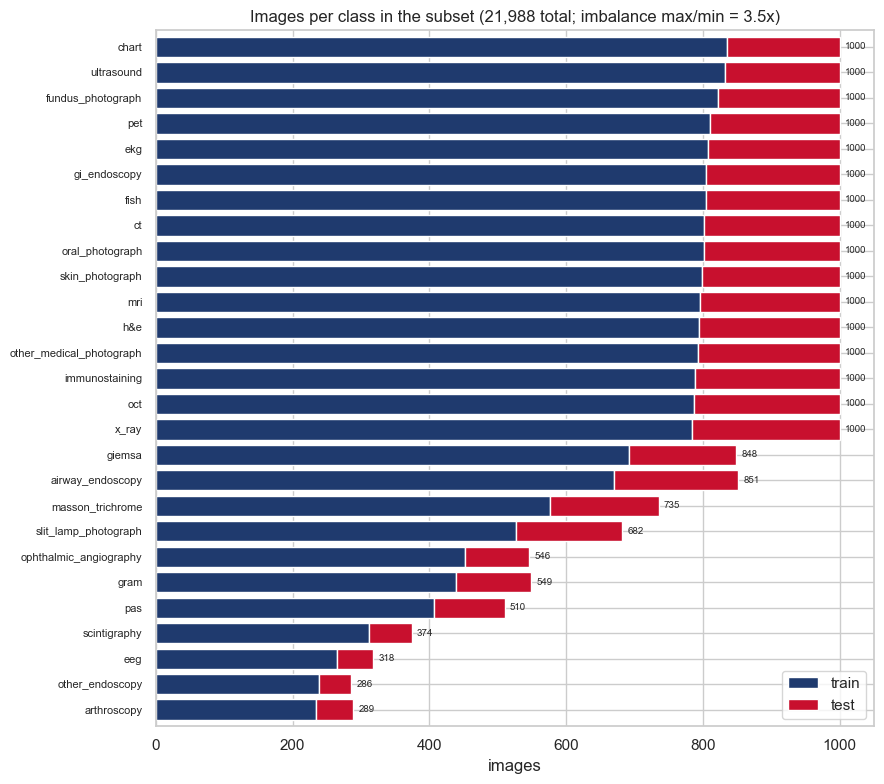

In [3]:
cnt = pd.DataFrame({"train": np.bincount(y[tr_all], minlength=K), "test": np.bincount(y[te], minlength=K)}, index=class_names).sort_values("train")
fig, ax = plt.subplots(figsize=(9, 8)); cnt.plot.barh(ax=ax, stacked=True, color=["#1F3A6E", "#C8102E"], width=0.8)
for i_, (a_, b_) in enumerate(zip(cnt.train, cnt.test)): ax.text(a_ + b_ + 8, i_, f"{a_ + b_}", va="center", fontsize=7)
ax.set_xlabel("images"); ax.set_title(f"Images per class in the subset ({cnt.values.sum():,} total; imbalance max/min = {cnt.sum(axis=1).max() / cnt.sum(axis=1).min():.1f}x)"); ax.tick_params(axis="y", labelsize=8)
savefig("29_class_distribution.png")

## 2. Models

In [4]:
MODELS = {
    "LogReg":       lambda: LogisticRegression(max_iter=300, C=0.1),
    "LinearSVM":    lambda: SGDClassifier(loss="hinge", alpha=1e-3, max_iter=30, tol=None, n_jobs=-1, random_state=SEED),   # linear SVM trained by SGD (fast)
    "SVM-RBF":      lambda: SVC(C=10, gamma="scale", decision_function_shape="ovr"),
    "kNN":          lambda: KNeighborsClassifier(15, weights="distance", n_jobs=-1),
    "RandomForest": lambda: RandomForestClassifier(300, n_jobs=-1, random_state=SEED),
    "MLP":          lambda: MLPClassifier((256,), early_stopping=True, max_iter=200, random_state=SEED),
}
if HAS_XGB: MODELS["XGBoost"] = lambda: XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.1, tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0)
HEAVY = {"SVM-RBF", "kNN", "XGBoost"}                      # skipped on the 2806-feature set (too slow / poor in high dimensions)
if FAST: MODELS = {k: v for k, v in MODELS.items() if k in ("LogReg", "LinearSVM", "RandomForest")}
elif not FULL_GRID: MODELS = {k: v for k, v in MODELS.items() if k not in ("RandomForest", "XGBoost")}   # Section 9 tunes RF/XGBoost on LDA features anyway
def scores(m, X):
    if hasattr(m, "predict_proba"): return m.predict_proba(X)
    return softmax(m.decision_function(X), axis=1)
def fit_predict(mname, fs, tr, ev, key):
    A, B = build(fs, tr, ev, key); m = MODELS[mname]().fit(A, y[tr])
    return m, m.predict(A), m.predict(B), A, B

## 3. Evaluation grid: 80/20 split and grouped k-fold CV
For every feature set and model: train accuracy, **test accuracy** (the 20% hold-out), macro-F1, and the **mean +/- std of the CV accuracy** over the article-grouped folds. This can take a while (roughly 1-2 hours on CPU for the full grid; set `FAST = True` first for a 10-minute check).

In [5]:
rows = []; t_start = time.time()
for fs in FSETS:
    for mn in MODELS:
        if fs == "All features" and mn in HEAVY: continue
        t0 = time.time(); m, ptr, pte, A, B = fit_predict(mn, fs, tr_all, te, key="test")
        row = dict(features=fs, model=mn, n_features=A.shape[1], train_acc=accuracy_score(y[tr_all], ptr), test_acc=accuracy_score(y[te], pte), test_macroF1=f1_score(y[te], pte, average="macro"), fit_s=time.time() - t0)
        cv = []
        for f in CV_FOLDS:
            tr_f, va_f = tr_all[fold[tr_all] != f], tr_all[fold[tr_all] == f]
            _, _, pva, _, _ = fit_predict(mn, fs, tr_f, va_f, key=f"cv{f}"); cv.append(accuracy_score(y[va_f], pva))
        row.update(cv_acc=np.mean(cv), cv_std=np.std(cv)); rows.append(row)
        print(f"{fs:15s} {mn:13s} d={A.shape[1]:5d} train={row['train_acc']:.3f} CV={row['cv_acc']:.3f}+/-{row['cv_std']:.3f} test={row['test_acc']:.3f} F1={row['test_macroF1']:.3f} ({time.time()-t0:.0f}s)")
grid = pd.DataFrame(rows).sort_values("cv_acc", ascending=False).reset_index(drop=True); grid.round(4).to_csv(os.path.join(RES, "model_grid.csv"), index=False)
print("total time: %.1f min" % ((time.time() - t_start) / 60)); grid.round(3)

All features    LogReg        d= 5878 train=1.000 CV=0.788+/-0.009 test=0.794 F1=0.780 (170s)
All features    LinearSVM     d= 5878 train=0.924 CV=0.780+/-0.008 test=0.786 F1=0.770 (88s)
All features    RandomForest  d= 5878 train=1.000 CV=0.774+/-0.010 test=0.794 F1=0.768 (598s)
All features    MLP           d= 5878 train=0.983 CV=0.795+/-0.006 test=0.809 F1=0.795 (437s)
LDA             LogReg        d=   26 train=0.804 CV=0.787+/-0.009 test=0.797 F1=0.783 (37s)
LDA             LinearSVM     d=   26 train=0.773 CV=0.747+/-0.011 test=0.763 F1=0.760 (1s)
LDA             SVM-RBF       d=   26 train=0.904 CV=0.783+/-0.009 test=0.792 F1=0.777 (127s)
LDA             kNN           d=   26 train=1.000 CV=0.787+/-0.008 test=0.793 F1=0.778 (6s)
LDA             RandomForest  d=   26 train=1.000 CV=0.791+/-0.006 test=0.796 F1=0.777 (52s)
LDA             MLP           d=   26 train=0.830 CV=0.787+/-0.007 test=0.792 F1=0.779 (24s)
LDA             XGBoost       d=   26 train=0.996 CV=0.782+/-0.011 t

,features,model,n_features,train_acc,test_acc,test_macroF1,fit_s,cv_acc,cv_std
0,All features,MLP,5878,0.983,0.809,0.795,127.070,0.795,0.006
1,LDA,RandomForest,26,1.000,0.796,0.777,13.574,0.791,0.006
2,All features,LogReg,5878,1.000,0.794,0.780,46.112,0.788,0.009
3,LDA,LogReg,26,0.804,0.797,0.783,9.318,0.787,0.009
4,LDA,MLP,26,0.830,0.792,0.779,7.307,0.787,0.007
5,LDA,kNN,26,1.000,0.793,0.778,3.089,0.787,0.008
6,PCA-100,SVM-RBF,100,0.999,0.793,0.781,74.673,0.784,0.007
7,LDA,SVM-RBF,26,0.904,0.792,0.777,36.710,0.783,0.009
8,LDA,XGBoost,26,0.996,0.784,0.770,16.191,0.782,0.011
9,All features,LinearSVM,5878,0.924,0.786,0.770,22.748,0.780,0.008


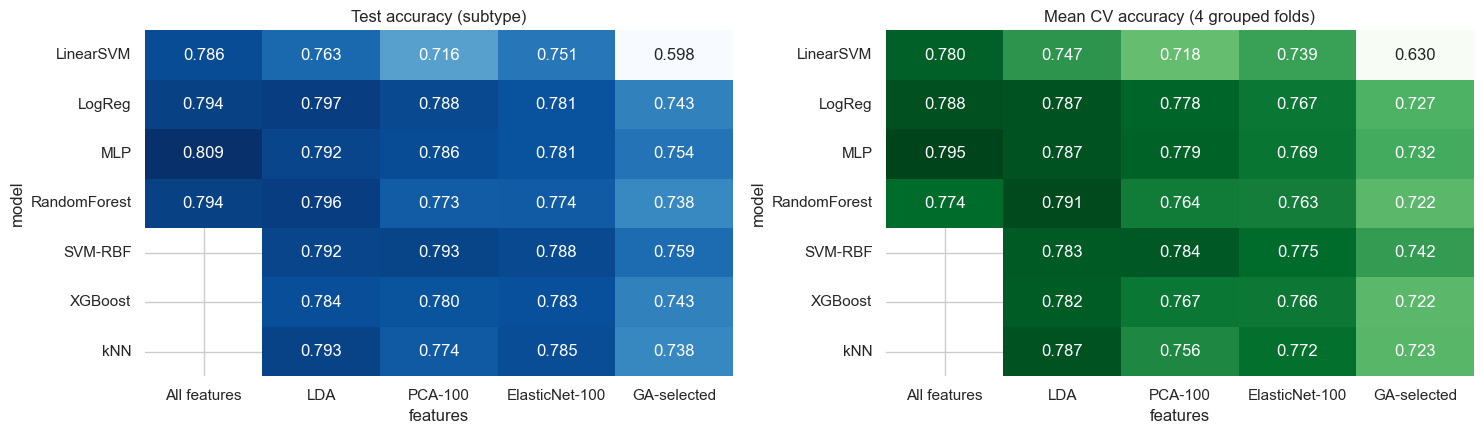

In [6]:
pv = grid.pivot(index="model", columns="features", values="test_acc")[[c for c in FSETS if c in grid.features.unique()]]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5)); sns.heatmap(pv, annot=True, fmt=".3f", cmap="Blues", ax=ax[0], cbar=False); ax[0].set_title(f"Test accuracy ({TARGET})")
pc = grid.pivot(index="model", columns="features", values="cv_acc")[pv.columns]; sns.heatmap(pc, annot=True, fmt=".3f", cmap="Greens", ax=ax[1], cbar=False); ax[1].set_title(f"Mean CV accuracy ({len(CV_FOLDS)} grouped folds)")
savefig("20_model_grid.png")

### Visual: cost and overfitting of every model
Left: accuracy against training time (log scale). Right: each model's train accuracy against its test accuracy. Points far below the diagonal are overfitting.

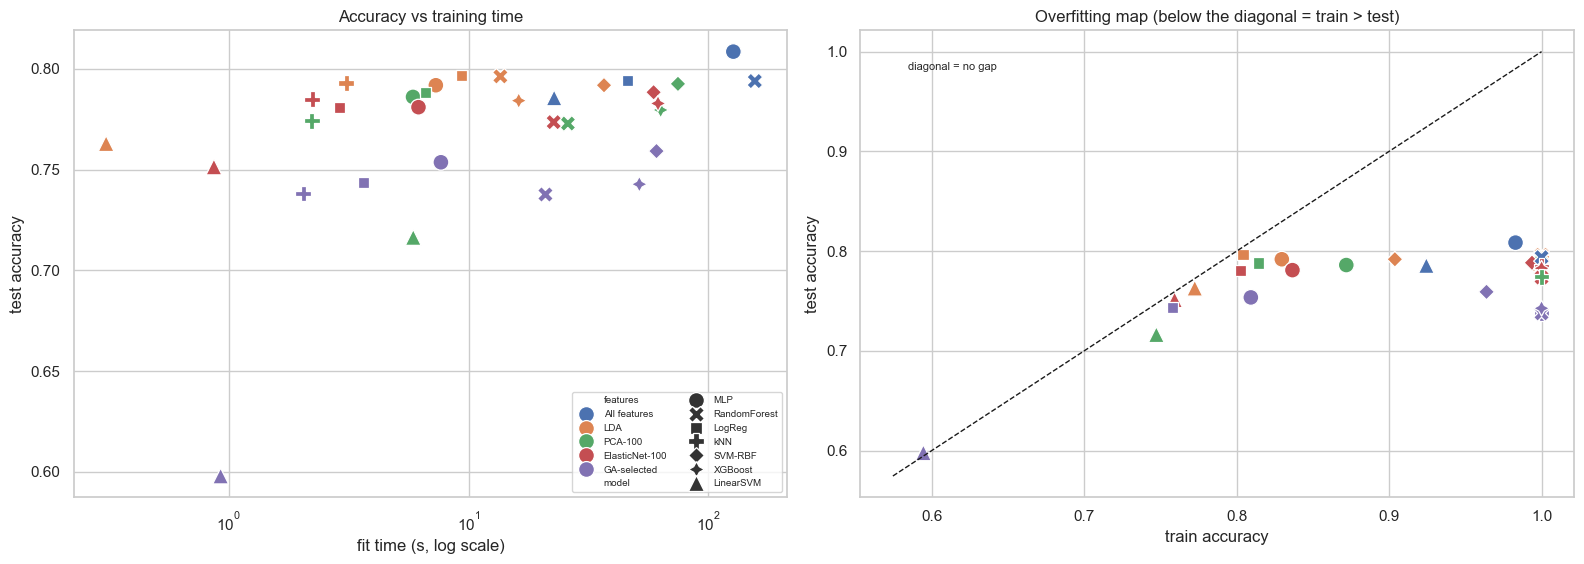

In [7]:
gg = grid.copy()
fig, ax = plt.subplots(1, 2, figsize=(16, 5.8))
sns.scatterplot(data=gg, x="fit_s", y="test_acc", hue="features", style="model", s=130, ax=ax[0]); ax[0].set_xscale("log"); ax[0].set_xlabel("fit time (s, log scale)"); ax[0].set_ylabel("test accuracy"); ax[0].set_title("Accuracy vs training time")
ax[0].legend(fontsize=7, ncol=2, loc="lower right")
sns.scatterplot(data=gg, x="train_acc", y="test_acc", hue="features", style="model", s=130, ax=ax[1], legend=False)
lo_ = min(gg.train_acc.min(), gg.test_acc.min()) - 0.02; ax[1].plot([lo_, 1.0], [lo_, 1.0], "k--", lw=1); ax[1].text(lo_ + 0.01, 0.99, "diagonal = no gap", fontsize=8, va="top")
ax[1].set_xlabel("train accuracy"); ax[1].set_ylabel("test accuracy"); ax[1].set_title("Overfitting map (below the diagonal = train > test)")
savefig("30_time_and_overfit_map.png")

## 4. Best model: full evaluation on the 20% test set

The best configuration is chosen by **cross-validation accuracy** (not by the test set), then evaluated once on the test set.

In [8]:
best = grid.iloc[0]; print("BEST by CV:", best.features, "+", best.model, f"| CV={best.cv_acc:.3f} test={best.test_acc:.3f}")
m, ptr, pte, A, B = fit_predict(best.model, best.features, tr_all, te, key="best")
P = scores(m, B); yt = y[te]
acc = accuracy_score(yt, pte); prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(yt, pte, average="macro", zero_division=0)
prec_w, rec_w, f1_w, _ = precision_recall_fscore_support(yt, pte, average="weighted", zero_division=0)
try: auc = roc_auc_score(yt, P, multi_class="ovr", average="macro", labels=np.arange(K))
except Exception as e: auc = np.nan; print("AUC problem:", e)
summary = pd.Series({"Accuracy": acc, "Error rate": 1 - acc, "Precision (macro)": prec_m, "Recall (macro)": rec_m, "F-measure (macro)": f1_m,
                     "Precision (weighted)": prec_w, "Recall (weighted)": rec_w, "F-measure (weighted)": f1_w, "ROC-AUC (OvR macro)": auc}).round(4)
summary.to_csv(os.path.join(RES, "best_model_metrics.csv"), header=["value"]); joblib.dump(m, os.path.join(RES, "best_model.joblib")); summary

BEST by CV: All features + MLP | CV=0.795 test=0.809


Accuracy                0.8086
Error rate              0.1914
Precision (macro)       0.8023
Recall (macro)          0.7914
F-measure (macro)       0.7952
Precision (weighted)    0.8112
Recall (weighted)       0.8086
F-measure (weighted)    0.8087
ROC-AUC (OvR macro)     0.9862
dtype: float64

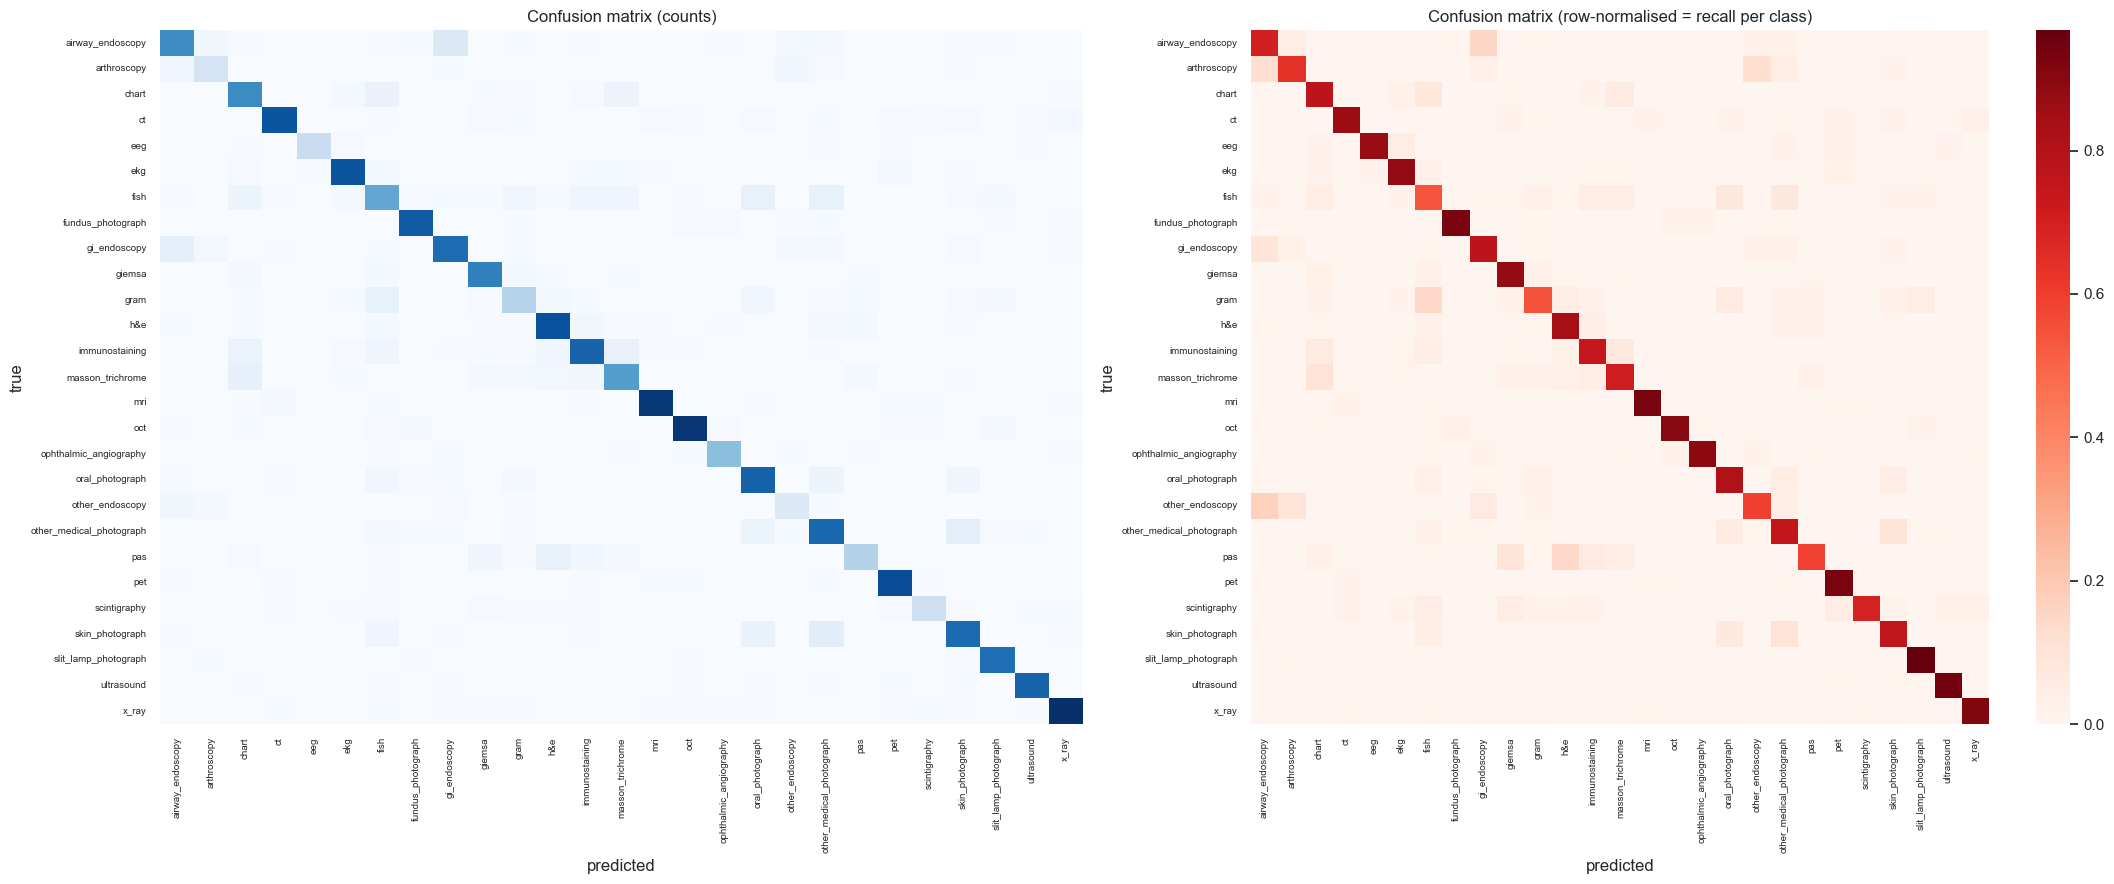

,true,predicted as,count,share of true class
0,airway_endoscopy,gi_endoscopy,28,0.15
1,skin_photograph,other_medical_photograph,22,0.11
2,other_medical_photograph,skin_photograph,20,0.10
3,gi_endoscopy,airway_endoscopy,19,0.10
4,masson_trichrome,chart,17,0.11
5,fish,other_medical_photograph,16,0.08
6,gram,fish,16,0.15
7,fish,oral_photograph,15,0.08
8,immunostaining,masson_trichrome,15,0.07
9,pas,h&e,15,0.15


In [9]:
cm = confusion_matrix(yt, pte, labels=np.arange(K)); cmn = cm / cm.sum(1, keepdims=True).clip(1)
fig, ax = plt.subplots(1, 2, figsize=(22, 9))
sns.heatmap(cm, annot=K <= 12, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax[0], cbar=False); ax[0].set_title("Confusion matrix (counts)")
sns.heatmap(cmn, annot=False, cmap="Reds", xticklabels=class_names, yticklabels=class_names, ax=ax[1]); ax[1].set_title("Confusion matrix (row-normalised = recall per class)")
for a in ax: a.set_xlabel("predicted"); a.set_ylabel("true"); a.tick_params(labelsize=7)
savefig("21_confusion_matrix.png")
off = [(class_names[i], class_names[j], cm[i, j], round(cmn[i, j], 2)) for i in range(K) for j in range(K) if i != j and cm[i, j] > 0]
pd.DataFrame(sorted(off, key=lambda t: -t[2])[:12], columns=["true", "predicted as", "count", "share of true class"])

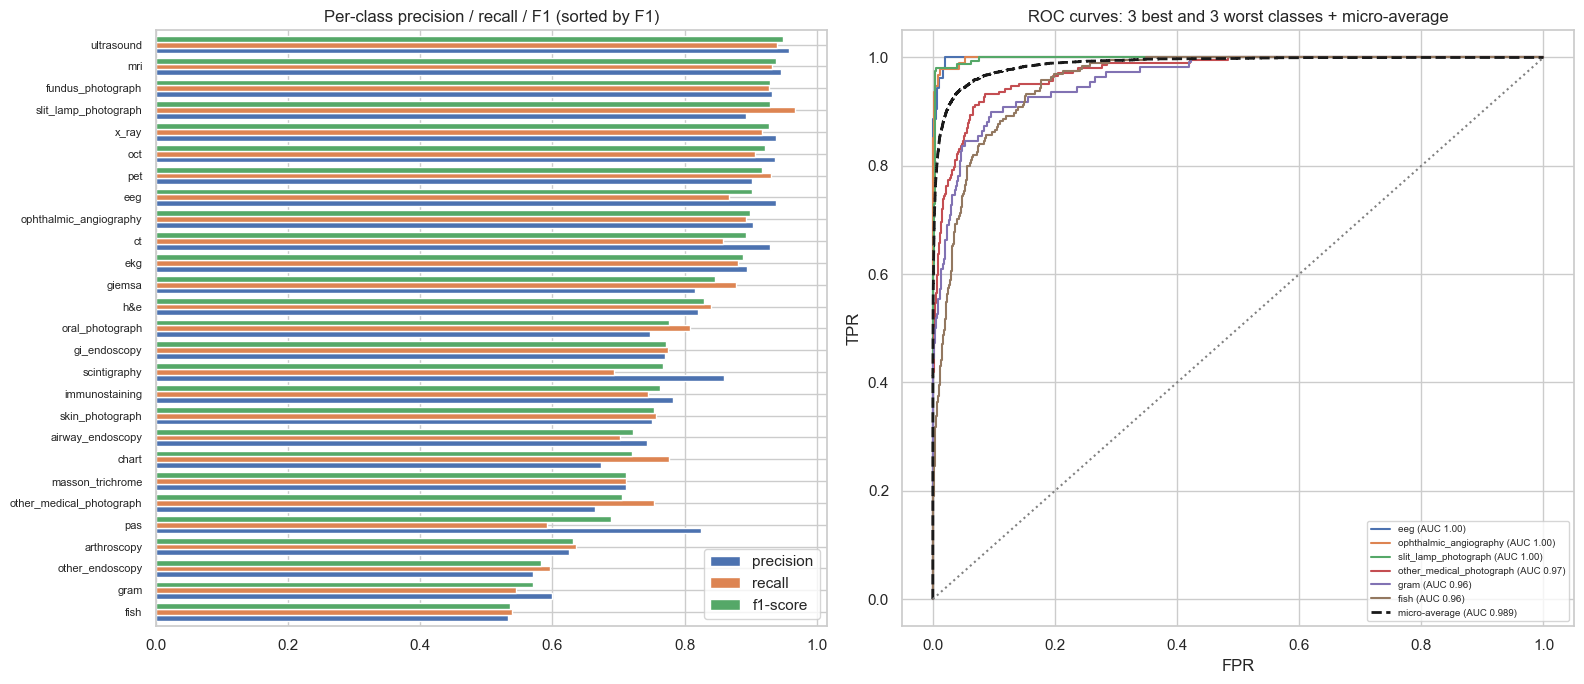

weakest classes: [np.str_('fish'), np.str_('gram'), np.str_('other_endoscopy'), np.str_('arthroscopy'), np.str_('pas')] | strongest: [np.str_('fundus_photograph'), np.str_('mri'), np.str_('ultrasound')]


In [10]:
rep = pd.DataFrame(classification_report(yt, pte, labels=np.arange(K), target_names=class_names, output_dict=True, zero_division=0)).T.iloc[:K].sort_values("f1-score")
rep.round(3).to_csv(os.path.join(RES, "per_class_report.csv"))
fig, ax = plt.subplots(1, 2, figsize=(16, 7)); rep[["precision", "recall", "f1-score"]].plot.barh(ax=ax[0], width=0.8); ax[0].set_title("Per-class precision / recall / F1 (sorted by F1)"); ax[0].tick_params(axis="y", labelsize=8)
Y = label_binarize(yt, classes=np.arange(K)); aucs = [roc_auc_score(Y[:, k], P[:, k]) for k in range(K) if Y[:, k].sum() > 0]; order = np.argsort([-a for a in aucs])
cls_ok = [k for k in range(K) if Y[:, k].sum() > 0]; show = [cls_ok[i] for i in list(order[:3]) + list(order[-3:])]
for k in show: fpr, tpr, _ = roc_curve(Y[:, k], P[:, k]); ax[1].plot(fpr, tpr, label=f"{class_names[k]} (AUC {roc_auc_score(Y[:, k], P[:, k]):.2f})")
fpr, tpr, _ = roc_curve(Y.ravel(), P.ravel()); ax[1].plot(fpr, tpr, "k--", lw=2, label=f"micro-average (AUC {roc_auc_score(Y.ravel(), P.ravel()):.3f})"); ax[1].plot([0, 1], [0, 1], ":", c="grey")
ax[1].set_title("ROC curves: 3 best and 3 worst classes + micro-average"); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].legend(fontsize=7); savefig("22_per_class_and_roc.png")
print("weakest classes:", list(rep.index[:5]), "| strongest:", list(rep.index[-3:]))

### Visual: is the weak performance caused by small classes? Is the model confident when it is wrong?
Left: F1 of each class against its number of test images. Middle: confidence of correct and wrong predictions. Right: accuracy if we keep only the most confident predictions (useful for a clinical decision-support story).

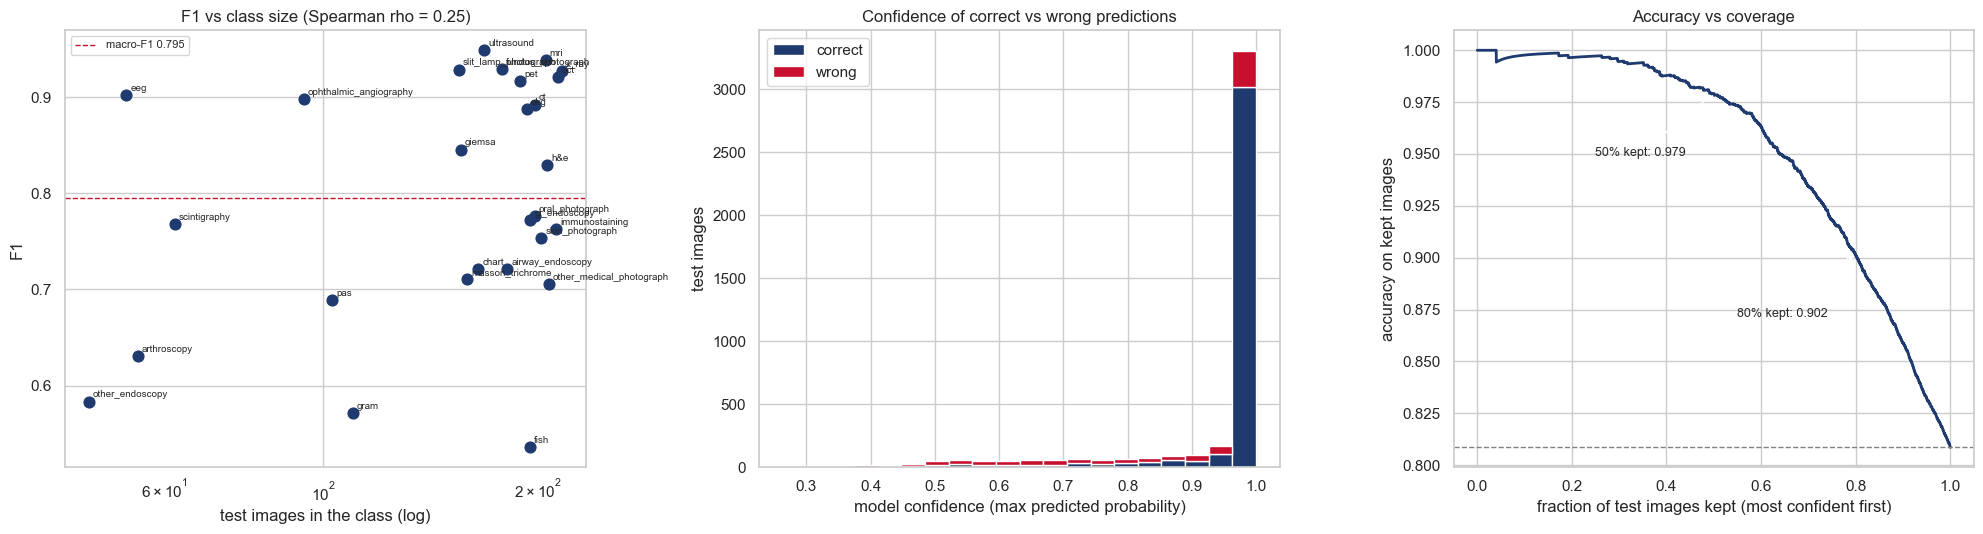

mean confidence: correct 0.969 | wrong 0.807


In [11]:
from scipy.stats import spearmanr
sup = np.bincount(yt, minlength=K); f1c = f1_score(yt, pte, labels=np.arange(K), average=None, zero_division=0)
dd = pd.DataFrame(dict(cls=class_names, support=sup, f1=f1c)); dd = dd[dd.support > 0]; rho = spearmanr(dd.support, dd.f1)[0]
conf = P.max(1); ok = (pte == yt)
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
ax[0].scatter(dd.support, dd.f1, s=60, c="#1F3A6E")
for r_ in dd.itertuples(): ax[0].annotate(r_.cls, (r_.support, r_.f1), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax[0].set_xscale("log"); ax[0].axhline(f1_m, ls="--", c="#C8102E", lw=1, label=f"macro-F1 {f1_m:.3f}"); ax[0].set_xlabel("test images in the class (log)"); ax[0].set_ylabel("F1"); ax[0].set_title(f"F1 vs class size (Spearman rho = {rho:.2f})"); ax[0].legend(fontsize=8)
ax[1].hist([conf[ok], conf[~ok]], bins=20, stacked=True, label=["correct", "wrong"], color=["#1F3A6E", "#C8102E"]); ax[1].set_xlabel("model confidence (max predicted probability)"); ax[1].set_ylabel("test images"); ax[1].set_title("Confidence of correct vs wrong predictions"); ax[1].legend()
o_ = np.argsort(-conf); cum_ = np.cumsum(ok[o_]) / np.arange(1, len(o_) + 1); cov_ = np.arange(1, len(o_) + 1) / len(o_)
ax[2].plot(cov_, cum_, color="#1F3A6E", lw=2); ax[2].axhline(acc, ls="--", c="grey", lw=1); ax[2].set_xlabel("fraction of test images kept (most confident first)"); ax[2].set_ylabel("accuracy on kept images"); ax[2].set_title("Accuracy vs coverage")
for q_ in (0.5, 0.8): ax[2].annotate(f"{q_:.0%} kept: {cum_[int(q_ * len(cum_)) - 1]:.3f}", (q_, cum_[int(q_ * len(cum_)) - 1]), xytext=(q_ - 0.25, cum_[int(q_ * len(cum_)) - 1] - 0.03), arrowprops=dict(arrowstyle="->"), fontsize=9)
savefig("31_size_confidence_coverage.png")
print(f"mean confidence: correct {conf[ok].mean():.3f} | wrong {conf[~ok].mean():.3f}")

## 5. Overfitting / underfitting analysis

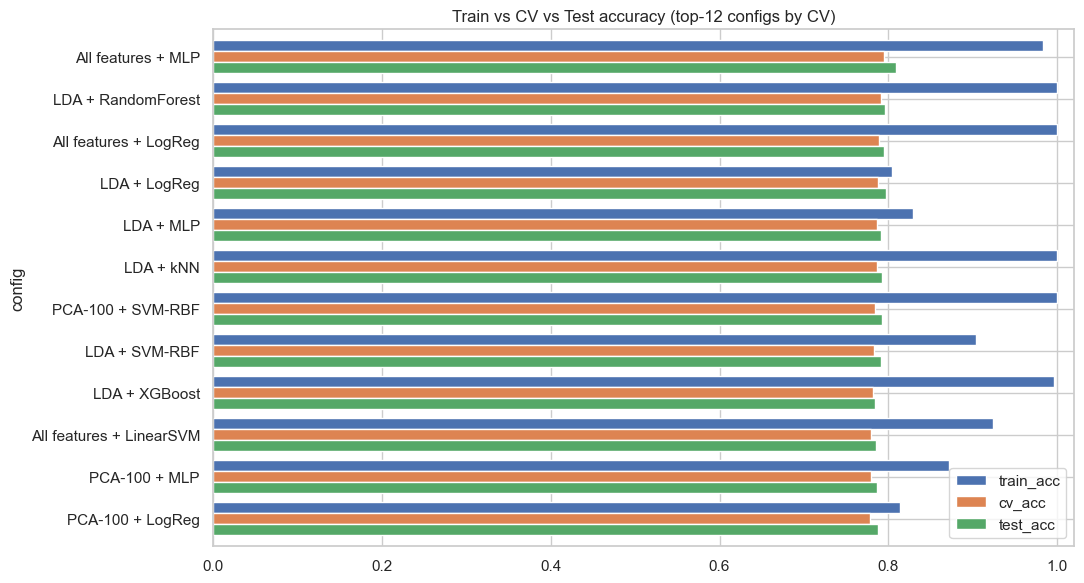

,features,model,train_acc,cv_acc,test_acc,gap_train_test,diagnosis
0,All features,MLP,0.983,0.795,0.809,0.174,"overfitting (high train, much lower test)"
1,LDA,RandomForest,1.000,0.791,0.796,0.204,"overfitting (high train, much lower test)"
2,All features,LogReg,1.000,0.788,0.794,0.206,"overfitting (high train, much lower test)"
3,LDA,LogReg,0.804,0.787,0.797,0.007,reasonably balanced
4,LDA,MLP,0.830,0.787,0.792,0.038,reasonably balanced
5,LDA,kNN,1.000,0.787,0.793,0.207,"overfitting (high train, much lower test)"
6,PCA-100,SVM-RBF,0.999,0.784,0.793,0.207,"overfitting (high train, much lower test)"
7,LDA,SVM-RBF,0.904,0.783,0.792,0.112,reasonably balanced
8,LDA,XGBoost,0.996,0.782,0.784,0.212,"overfitting (high train, much lower test)"
9,All features,LinearSVM,0.924,0.780,0.786,0.139,reasonably balanced


In [12]:
g = grid.copy(); g["gap_train_test"] = g.train_acc - g.test_acc; g["gap_cv_test"] = (g.cv_acc - g.test_acc).abs()
def verdict(r):
    if r.train_acc > 0.9 and r.gap_train_test > 0.15: return "overfitting (high train, much lower test)"
    if r.train_acc < 0.6: return "underfitting (low train accuracy)"
    return "reasonably balanced" if r.gap_train_test < 0.15 else "mild overfitting"
g["diagnosis"] = g.apply(verdict, axis=1); g.round(3).to_csv(os.path.join(RES, "overfit_diagnosis.csv"), index=False)
top = g.head(12).copy(); top["config"] = top.features + " + " + top.model
top.set_index("config")[["train_acc", "cv_acc", "test_acc"]].plot.barh(figsize=(11, 6), width=0.8); plt.gca().invert_yaxis(); plt.title("Train vs CV vs Test accuracy (top-12 configs by CV)"); plt.xlim(0, 1.02); savefig("23_train_cv_test.png")
g[["features", "model", "train_acc", "cv_acc", "test_acc", "gap_train_test", "diagnosis"]].head(12).round(3)

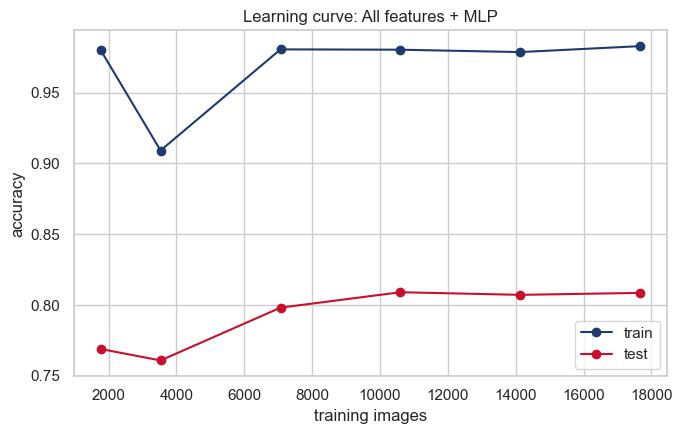

,fraction,n_train,train_acc,test_acc
0,0.1,1767,0.980,0.769
1,0.2,3534,0.909,0.761
2,0.4,7069,0.981,0.798
3,0.6,10603,0.980,0.809
4,0.8,14138,0.979,0.807
5,1.0,17673,0.983,0.809


In [13]:
fracs = [0.1, 0.2, 0.4, 0.6, 0.8, 1.0]; lc = []; rs = np.random.RandomState(SEED)
for fr in fracs:
    sub = np.sort(rs.choice(tr_all, int(len(tr_all) * fr), replace=False))
    mm, ptr_, pte_, _, _ = fit_predict(best.model, best.features, sub, te, key=f"lc{fr}")
    lc.append((fr, len(sub), accuracy_score(y[sub], ptr_), accuracy_score(y[te], pte_)))
lc = pd.DataFrame(lc, columns=["fraction", "n_train", "train_acc", "test_acc"])
plt.figure(figsize=(7, 4.5)); plt.plot(lc.n_train, lc.train_acc, "o-", label="train", color="#1F3A6E"); plt.plot(lc.n_train, lc.test_acc, "o-", label="test", color="#C8102E")
plt.xlabel("training images"); plt.ylabel("accuracy"); plt.title(f"Learning curve: {best.features} + {best.model}"); plt.legend(); savefig("24_learning_curve.png"); lc.round(3)

**How to read it:** a large train-test gap that shrinks with more data means variance (overfitting) and more data or stronger regularisation would help; a low train accuracy with a small gap means bias (underfitting), so a richer model or better features are needed; curves that have flattened mean the model has converged for this feature set.

## 6. Modality ablation: does fusion help?
Same classifier (Logistic Regression, C = 0.01) on each modality alone and on the fusion, using **all feature blocks** produced by Notebooks 02/03 (ResNet50, DINOv2, BiomedCLIP image, handcrafted, caption/case SVD text, BiomedCLIP text, tabular). In the first version of this table only the older 2,806 columns were used, which understated the benefit of fusion.

['Image: ResNet50', 2048, 0.7525, 0.7363, 25.4]
['Image: DINOv2', 1536, 0.7747, 0.7548, 35.6]
['Image: BiomedCLIP', 512, 0.7835, 0.766, 8.1]
['Image: handcrafted', 347, 0.4818, 0.4357, 4.9]
['Image: all 4 blocks', 4443, 0.7961, 0.7814, 95.1]
['Text: caption SVD', 200, 0.6202, 0.6037, 1.0]
['Text: caption BiomedCLIP', 512, 0.6922, 0.6738, 5.5]
['Text: case SVD', 200, 0.3261, 0.3031, 1.1]
['Text: case BiomedCLIP', 512, 0.3337, 0.3044, 6.9]
['Text: all 4 blocks', 1424, 0.6816, 0.6668, 16.0]
['Tabular (age, gender)', 11, 0.0735, 0.0234, 0.4]
['Image (all) + caption text', 5155, 0.8042, 0.7924, 73.5]
['FUSION (all 9 blocks)', 5878, 0.8028, 0.7895, 75.8]


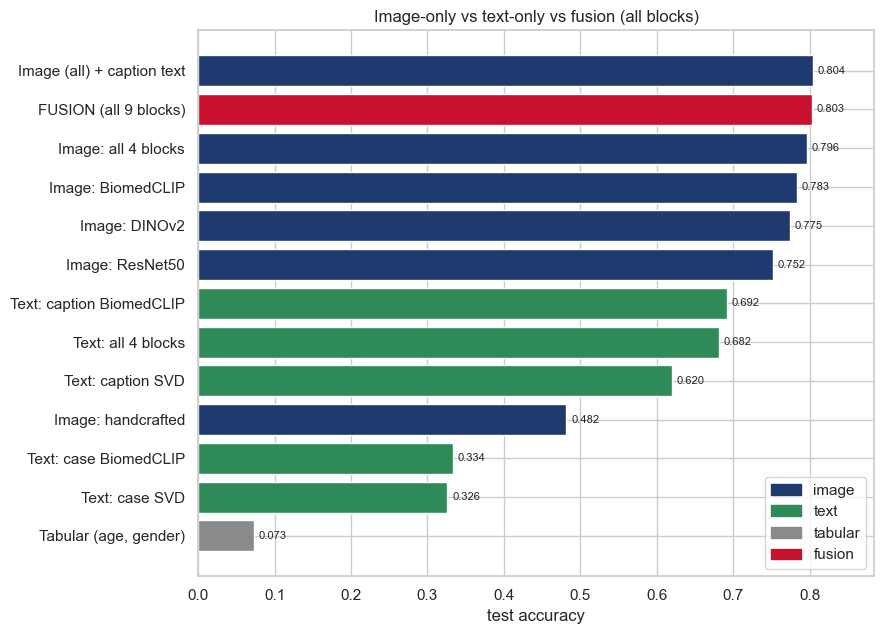

,modality,n_features,test_acc,test_macroF1,s
10,"Tabular (age, gender)",11,0.0735,0.0234,0.4
7,Text: case SVD,200,0.3261,0.3031,1.1
8,Text: case BiomedCLIP,512,0.3337,0.3044,6.9
3,Image: handcrafted,347,0.4818,0.4357,4.9
5,Text: caption SVD,200,0.6202,0.6037,1.0
9,Text: all 4 blocks,1424,0.6816,0.6668,16.0
6,Text: caption BiomedCLIP,512,0.6922,0.6738,5.5
0,Image: ResNet50,2048,0.7525,0.7363,25.4
1,Image: DINOv2,1536,0.7747,0.7548,35.6
2,Image: BiomedCLIP,512,0.7835,0.7660,8.1


In [14]:
IMG = ["resnet", "dinov2", "biomedclip", "handcrafted"]; TXT = ["caption_svd", "case_svd", "bm_caption", "bm_case"]
combos = {"Image: ResNet50": ["resnet"], "Image: DINOv2": ["dinov2"], "Image: BiomedCLIP": ["biomedclip"], "Image: handcrafted": ["handcrafted"],
          "Image: all 4 blocks": IMG,
          "Text: caption SVD": ["caption_svd"], "Text: caption BiomedCLIP": ["bm_caption"], "Text: case SVD": ["case_svd"], "Text: case BiomedCLIP": ["bm_case"],
          "Text: all 4 blocks": TXT, "Tabular (age, gender)": ["tabular"],
          "Image (all) + caption text": IMG + ["caption_svd", "bm_caption"],
          "FUSION (all 9 blocks)": IMG + TXT + ["tabular"]}
ab = []
for nm, bl in combos.items():
    cols = np.where(np.isin(block, bl))[0]
    if len(cols) == 0: continue
    t0 = time.time(); m_ = LogisticRegression(max_iter=300, C=0.01).fit(Xs[tr_all][:, cols], y[tr_all]); p_ = m_.predict(Xs[te][:, cols])
    ab.append([nm, len(cols), round(accuracy_score(y[te], p_), 4), round(f1_score(y[te], p_, average="macro"), 4), round(time.time() - t0, 1)]); print(ab[-1])
ab = pd.DataFrame(ab, columns=["modality", "n_features", "test_acc", "test_macroF1", "s"]).sort_values("test_acc"); ab.to_csv(os.path.join(RES, "modality_ablation.csv"), index=False)
from matplotlib.patches import Patch
grp = lambda s: "#C8102E" if "FUSION" in s else ("#1F3A6E" if s.startswith("Image") else ("#2E8B57" if s.startswith("Text") else "#8A8A8A"))
plt.figure(figsize=(9, 6.5)); bars_ = plt.barh(ab.modality, ab.test_acc, color=[grp(s_) for s_ in ab.modality])
for b_, v_ in zip(bars_, ab.test_acc): plt.text(v_ + 0.006, b_.get_y() + b_.get_height() / 2, f"{v_:.3f}", va="center", fontsize=8)
plt.legend(handles=[Patch(color="#1F3A6E", label="image"), Patch(color="#2E8B57", label="text"), Patch(color="#8A8A8A", label="tabular"), Patch(color="#C8102E", label="fusion")], loc="lower right")
plt.xlim(0, min(1, ab.test_acc.max() + 0.08)); plt.xlabel("test accuracy"); plt.title("Image-only vs text-only vs fusion (all blocks)"); plt.tight_layout(); savefig("25_modality_ablation.png"); ab

## 7. Comparison with related work
Numbers below come from the cited sources only. The MultiCaRe dataset paper (Nievas Offidani et al., *Data* 2025, 10(8):123) trains thirteen ResNet50 models on the 81-class taxonomy and reports accuracy and F1 only as confusion matrices in the GitHub repository, so no single accuracy is quoted here. It does report the quality of the labels, which gives a useful ceiling for our task: **90% of caption-based labels and 70% of ML-based labels were correct** (mean ML-label error 25.3% in a random review). BiomedCLIP (Zhang et al., 2023) is added for context: it is the encoder behind our `biomedclip` and `bm_*` blocks, but its published numbers are zero-shot results on other tasks, so they are **not directly comparable**.

In [15]:
ours = grid.iloc[0]; img_only = ab.set_index("modality").loc["Image: ResNet50"] if "Image: ResNet50" in set(ab.modality) else None
img_bm = ab.set_index("modality").loc["Image: BiomedCLIP"] if "Image: BiomedCLIP" in set(ab.modality) else None
fus = ab.set_index("modality").loc["FUSION (all 9 blocks)"] if "FUSION (all 9 blocks)" in set(ab.modality) else None
N_IMG = f"MultiCaRe subset ({len(y):,} imgs)"; TASK = f"{TARGET} ({K} classes)"; fmt = lambda r: f"{r.test_acc:.3f} / {r.test_macroF1:.3f}" if r is not None else "n/a"
related = pd.DataFrame([
    ["Nievas Offidani et al. 2025 (MultiCaRe dataset paper)", "MultiCaRe, full 130k images", "ResNet50 ensemble (13 models), image only", "taxonomy labels (81 classes)", "accuracy, F1", "per-class numbers only in the GitHub confusion matrices; label quality: 90% (caption) / 70% (ML) correct"],
    ["Zhang et al. 2023 (BiomedCLIP)", "PCam, LC25000, TCGA-TIL, RSNA (other tasks)", "BiomedCLIP ViT-B/16, zero-shot", "pathology / radiology classification", "accuracy (AUROC for TCGA-TIL)", "mean 75.5% at 224 px (not comparable)"],
    ["This work: image-only, ResNet50", N_IMG, "ResNet50 embeddings + Logistic Regression", TASK, "accuracy / macro-F1", fmt(img_only)],
    ["This work: image-only, BiomedCLIP", N_IMG, "BiomedCLIP image embeddings + Logistic Regression", TASK, "accuracy / macro-F1", fmt(img_bm)],
    ["This work: fusion of all blocks", N_IMG, "9 feature blocks + Logistic Regression (C = 0.01)", TASK, "accuracy / macro-F1", fmt(fus)],
    ["This work: best model (Section 3, by CV)", N_IMG, f"{ours.features} + {ours.model}", TASK, "accuracy / macro-F1", fmt(ours)]],
    columns=["Work", "Data", "Model", "Task", "Metric", "Result"])
related.to_csv(os.path.join(RES, "related_work_table.csv"), index=False); related

,Work,Data,Model,Task,Metric,Result
0,Nievas Offidani et al. 2025 (MultiCaRe dataset...,"MultiCaRe, full 130k images","ResNet50 ensemble (13 models), image only",taxonomy labels (81 classes),"accuracy, F1",per-class numbers only in the GitHub confusion...
1,Zhang et al. 2023 (BiomedCLIP),"PCam, LC25000, TCGA-TIL, RSNA (other tasks)","BiomedCLIP ViT-B/16, zero-shot",pathology / radiology classification,accuracy (AUROC for TCGA-TIL),mean 75.5% at 224 px (not comparable)
2,"This work: image-only, ResNet50","MultiCaRe subset (21,988 imgs)",ResNet50 embeddings + Logistic Regression,subtype (27 classes),accuracy / macro-F1,0.752 / 0.736
3,"This work: image-only, BiomedCLIP","MultiCaRe subset (21,988 imgs)",BiomedCLIP image embeddings + Logistic Regression,subtype (27 classes),accuracy / macro-F1,0.783 / 0.766
4,This work: fusion of all blocks,"MultiCaRe subset (21,988 imgs)",9 feature blocks + Logistic Regression (C = 0.01),subtype (27 classes),accuracy / macro-F1,0.803 / 0.789
5,"This work: best model (Section 3, by CV)","MultiCaRe subset (21,988 imgs)",All features + MLP,subtype (27 classes),accuracy / macro-F1,0.809 / 0.795


**Note on fairness when comparing:** other papers use different subsets, label sets (the original models use the 81-class taxonomy and the full 130k images) and splits, so differences are indicative only. Our split is grouped by article, which is stricter than random splits.

## 8. Summary for the report

In [16]:
print(f"Target: {TARGET} ({K} classes) | train {len(tr_all)} / test {len(te)} images (grouped by article)")
print(f"Best (by {len(CV_FOLDS)}-fold CV): {best.features} + {best.model}: CV {best.cv_acc:.3f} +/- {best.cv_std:.3f} | test accuracy {acc:.3f}, macro-F1 {f1_m:.3f}, ROC-AUC {auc:.3f}")
print("Ablation (LogReg, test acc): fusion of all blocks", ab.set_index("modality").loc["FUSION (all 9 blocks)"].test_acc, "| best single image block", ab[ab.modality.str.startswith("Image:")].test_acc.max(), "| ResNet50 alone", None if img_only is None else round(img_only.test_acc, 3))

Target: subtype (27 classes) | train 17673 / test 4315 images (grouped by article)
Best (by 4-fold CV): All features + MLP: CV 0.795 +/- 0.006 | test accuracy 0.809, macro-F1 0.795, ROC-AUC 0.986
Ablation (LogReg, test acc): fusion of all blocks 0.8028 | best single image block 0.7961 | ResNet50 alone 0.752


## 9. Tuning to reduce over- and under-fitting (new)
Every search space contains the **default** setting used in section 3, so before/after are compared on the **same folds** (`TUNE_FOLDS`). Hyper-parameters are chosen by article-grouped CV on the training rows only; the test set is used once at the end.
- **Over-fitting fixes:** stronger L2 for Logistic Regression and the MLP, smaller/limited trees, row/column sub-sampling and L2 for XGBoost, larger k for kNN.
- **Under-fitting fix:** the linear SVM (SGD) gets a smaller `alpha` and more epochs.
- **Variance reduction:** a soft-voting ensemble of the best tuned models.

In [17]:
TUNE_FOLDS = [1] if FAST else [1, 2]
SPACES = [
 ("All features", "LogReg",       [dict(C=c) for c in (0.1, 0.001, 0.003, 0.01, 0.03)]),
 ("All features", "LogRegBal",    [dict(C=c) for c in (0.003, 0.01)]),
 ("All features", "MLP",          [dict(alpha=1e-4, hidden=(256,))] + [dict(alpha=a, hidden=(128,)) for a in (1e-3, 1e-2, 1e-1, 1.0)]),
 ("LDA",          "LinearSVM",    [dict(alpha=1e-3, max_iter=30)] + [dict(alpha=a, max_iter=100) for a in (1e-5, 1e-4, 1e-3)]),
 ("LDA",          "kNN",          [dict(k=k) for k in (15, 25, 50)]),
 ("LDA",          "RandomForest", [dict(min_samples_leaf=1, max_depth=None)] + [dict(min_samples_leaf=l, max_depth=d) for l in (3, 10) for d in (12, 20)]),
 ("LDA",          "XGBoost",      [dict(n_estimators=150, max_depth=6, learning_rate=0.1)] + [dict(n_estimators=200, max_depth=d, learning_rate=0.1, subsample=0.7, colsample_bytree=0.5, reg_lambda=r) for d in (3, 4) for r in (1, 10)]),
]
if FAST: SPACES = [s_ for s_ in SPACES if s_[1] in ("LogReg", "LogRegBal", "kNN")]
if not HAS_XGB: SPACES = [s_ for s_ in SPACES if s_[1] != "XGBoost"]
def make_model(mn, p):
    if mn == "LogReg": return LogisticRegression(max_iter=300, **p)
    if mn == "LogRegBal": return LogisticRegression(max_iter=300, class_weight="balanced", **p)
    if mn == "MLP": return MLPClassifier(hidden_layer_sizes=p["hidden"], alpha=p["alpha"], early_stopping=True, max_iter=200, random_state=SEED)
    if mn == "RandomForest": return RandomForestClassifier(300, n_jobs=-1, random_state=SEED, **p)
    if mn == "XGBoost": return XGBClassifier(tree_method="hist", n_jobs=-1, random_state=SEED, verbosity=0, **p)
    if mn == "kNN": return KNeighborsClassifier(p["k"], weights="distance", n_jobs=-1)
    if mn == "LinearSVM": return SGDClassifier(loss="hinge", tol=None, n_jobs=-1, random_state=SEED, **p)
def cv_params(fs, mn, p):
    s_ = []
    for f in TUNE_FOLDS:
        tr_f, va_f = tr_all[fold[tr_all] != f], tr_all[fold[tr_all] == f]; A_, B_ = build(fs, tr_f, va_f, key=f"cv{f}")
        s_.append(accuracy_score(y[va_f], make_model(mn, p).fit(A_, y[tr_f]).predict(B_)))
    return np.mean(s_), np.std(s_)
trials, tuned = [], {}
t_start = time.time()
for fs, mn, space in SPACES:
    best_i, best_cv = None, -1; t0 = time.time()
    for i, p in enumerate(space):
        cvm, cvs = cv_params(fs, mn, p); trials.append(dict(features=fs, model=mn, params=str(p), is_default=(i == 0), cv_acc=cvm, cv_std=cvs))
        if cvm > best_cv: best_i, best_cv = i, cvm
    p = space[best_i]; A_, B_ = build(fs, tr_all, te, key="test"); m_ = make_model(mn, p).fit(A_, y[tr_all])
    tuned[(fs, mn)] = dict(params=p, model=m_, cv=best_cv, train=accuracy_score(y[tr_all], m_.predict(A_)), test=accuracy_score(y[te], m_.predict(B_)), f1=f1_score(y[te], m_.predict(B_), average="macro"))
    print(f"{fs:13s} {mn:12s} best={p} CV={best_cv:.3f} train={tuned[(fs, mn)]['train']:.3f} test={tuned[(fs, mn)]['test']:.3f} ({time.time()-t0:.0f}s)")
trials = pd.DataFrame(trials); trials.round(4).to_csv(os.path.join(RES, "tuning_trials.csv"), index=False); print("tuning time: %.1f min" % ((time.time() - t_start) / 60))

All features  LogReg       best={'C': 0.001} CV=0.809 train=0.943 test=0.815 (657s)
All features  LogRegBal    best={'C': 0.003} CV=0.806 train=0.986 test=0.810 (335s)
All features  MLP          best={'alpha': 0.1, 'hidden': (128,)} CV=0.802 train=0.979 test=0.805 (614s)
LDA           LinearSVM    best={'alpha': 0.0001, 'max_iter': 100} CV=0.779 train=0.797 test=0.785 (27s)
LDA           kNN          best={'k': 15} CV=0.791 train=1.000 test=0.793 (3s)
LDA           RandomForest best={'min_samples_leaf': 1, 'max_depth': None} CV=0.794 train=1.000 test=0.796 (91s)
LDA           XGBoost      best={'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.1, 'subsample': 0.7, 'colsample_bytree': 0.5, 'reg_lambda': 10} CV=0.791 train=0.923 test=0.788 (112s)
tuning time: 30.6 min


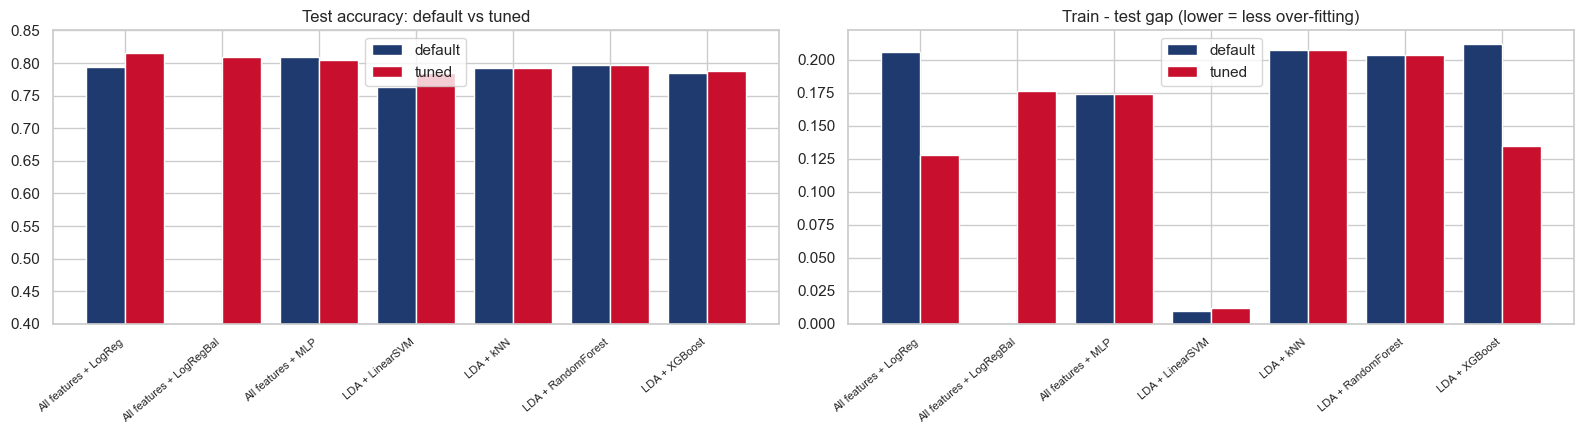

,features,model,best_params,default_cv,tuned_cv,cv_gain,default_gap,tuned_gap,default_test,tuned_test
0,All features,LogReg,{'C': 0.001},0.793,0.809,0.016,0.206,0.128,0.794,0.815
1,All features,LogRegBal,{'C': 0.003},0.806,0.806,0.000,NaN,0.177,NaN,0.810
2,All features,MLP,"{'alpha': 0.1, 'hidden': (128,)}",0.800,0.802,0.002,0.174,0.174,0.809,0.805
3,LDA,LinearSVM,"{'alpha': 0.0001, 'max_iter': 100}",0.756,0.779,0.023,0.010,0.012,0.763,0.785
4,LDA,kNN,{'k': 15},0.791,0.791,0.000,0.207,0.207,0.793,0.793
5,LDA,RandomForest,"{'min_samples_leaf': 1, 'max_depth': None}",0.794,0.794,0.000,0.204,0.204,0.796,0.796
6,LDA,XGBoost,"{'n_estimators': 200, 'max_depth': 4, 'learnin...",0.788,0.791,0.004,0.212,0.135,0.784,0.788


In [18]:
dfl = trials[trials.is_default].groupby(["features", "model"]).cv_acc.first().rename("default_cv")
rows = []
for (fs, mn), r in tuned.items():
    base = grid[(grid.features == fs) & (grid.model == mn)]
    rows.append(dict(features=fs, model=mn, best_params=str(r["params"]), default_cv=dfl.get((fs, mn), np.nan), tuned_cv=r["cv"], tuned_train=r["train"], tuned_test=r["test"], tuned_gap=r["train"] - r["test"],
                     default_train=base.train_acc.iloc[0] if len(base) else np.nan, default_test=base.test_acc.iloc[0] if len(base) else np.nan))
tun = pd.DataFrame(rows); tun["default_gap"] = tun.default_train - tun.default_test; tun["cv_gain"] = tun.tuned_cv - tun.default_cv; tun["gap_change"] = tun.tuned_gap - tun.default_gap
tun.round(3).to_csv(os.path.join(RES, "tuning_summary.csv"), index=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5)); lab = tun.features + " + " + tun.model; xx = np.arange(len(tun))
ax[0].bar(xx - 0.2, tun.default_test, 0.4, label="default", color="#1F3A6E"); ax[0].bar(xx + 0.2, tun.tuned_test, 0.4, label="tuned", color="#C8102E"); ax[0].set_xticks(xx); ax[0].set_xticklabels(lab, rotation=40, ha="right", fontsize=8)
ax[0].set_ylim(0.4, 0.85); ax[0].set_title("Test accuracy: default vs tuned"); ax[0].legend()
ax[1].bar(xx - 0.2, tun.default_gap, 0.4, label="default", color="#1F3A6E"); ax[1].bar(xx + 0.2, tun.tuned_gap, 0.4, label="tuned", color="#C8102E"); ax[1].set_xticks(xx); ax[1].set_xticklabels(lab, rotation=40, ha="right", fontsize=8)
ax[1].set_title("Train - test gap (lower = less over-fitting)"); ax[1].legend(); savefig("26_tuning_before_after.png")
tun[["features", "model", "best_params", "default_cv", "tuned_cv", "cv_gain", "default_gap", "tuned_gap", "default_test", "tuned_test"]].round(3)

### Soft-voting ensemble of the best tuned models

In [19]:
rank = sorted(tuned.items(), key=lambda kv: -kv[1]["cv"]); members = [k for k, _ in rank[:3]]; print("ensemble members:", members)
def ens_probs(members, tr, ev, key):
    out = []
    for fs, mn in members:
        A_, B_ = build(fs, tr, ev, key=key); out.append(scores(make_model(mn, tuned[(fs, mn)]["params"]).fit(A_, y[tr]), B_))
    return np.mean(out, axis=0)
cv_e = []
for f in TUNE_FOLDS:
    tr_f, va_f = tr_all[fold[tr_all] != f], tr_all[fold[tr_all] == f]; cv_e.append(accuracy_score(y[va_f], ens_probs(members, tr_f, va_f, f"cv{f}").argmax(1)))
Pe = ens_probs(members, tr_all, te, "test"); pe = Pe.argmax(1)
ens = dict(cv=np.mean(cv_e), test=accuracy_score(y[te], pe), f1=f1_score(y[te], pe, average="macro"))
try: ens["auc"] = roc_auc_score(y[te], Pe, multi_class="ovr", average="macro", labels=np.arange(K))
except Exception: ens["auc"] = np.nan
print({k: round(v, 4) for k, v in ens.items()})

ensemble members: [('All features', 'LogReg'), ('All features', 'LogRegBal'), ('All features', 'MLP')]
{'cv': np.float64(0.8097), 'test': 0.8151, 'f1': 0.8037, 'auc': 0.9886}


In [20]:
b_default = grid.iloc[0]; b_tuned = max(tuned.items(), key=lambda kv: kv[1]["cv"])
final = pd.DataFrame([
    ["Section 3 best (default params)", f"{b_default.features} + {b_default.model}", b_default.train_acc, b_default.test_acc, b_default.test_macroF1, b_default.train_acc - b_default.test_acc],
    ["Best tuned single model (by CV)", f"{b_tuned[0][0]} + {b_tuned[0][1]}", b_tuned[1]["train"], b_tuned[1]["test"], b_tuned[1]["f1"], b_tuned[1]["train"] - b_tuned[1]["test"]],
    ["Soft-voting ensemble (top-3 tuned)", " + ".join(f"{a}/{b}" for a, b in members), np.nan, ens["test"], ens["f1"], np.nan]],
    columns=["configuration", "features / models", "train_acc", "test_acc", "test_macroF1", "train-test gap"])
final.round(4).to_csv(os.path.join(RES, "final_comparison_after_tuning.csv"), index=False)
print(f"ensemble CV (folds {TUNE_FOLDS}) = {ens['cv']:.3f} | ROC-AUC = {ens['auc']:.3f}"); final.round(3)

ensemble CV (folds [1, 2]) = 0.810 | ROC-AUC = 0.989


,configuration,features / models,train_acc,test_acc,test_macroF1,train-test gap
0,Section 3 best (default params),All features + MLP,0.983,0.809,0.795,0.174
1,Best tuned single model (by CV),All features + LogReg,0.943,0.815,0.801,0.128
2,Soft-voting ensemble (top-3 tuned),All features/LogReg + All features/LogRegBal +...,NaN,0.815,0.804,NaN


### Visual: where does the ensemble help?
Per-class F1 of the default best model (Section 3) against the voting ensemble. Points to the right of the first marker are classes the ensemble improved.

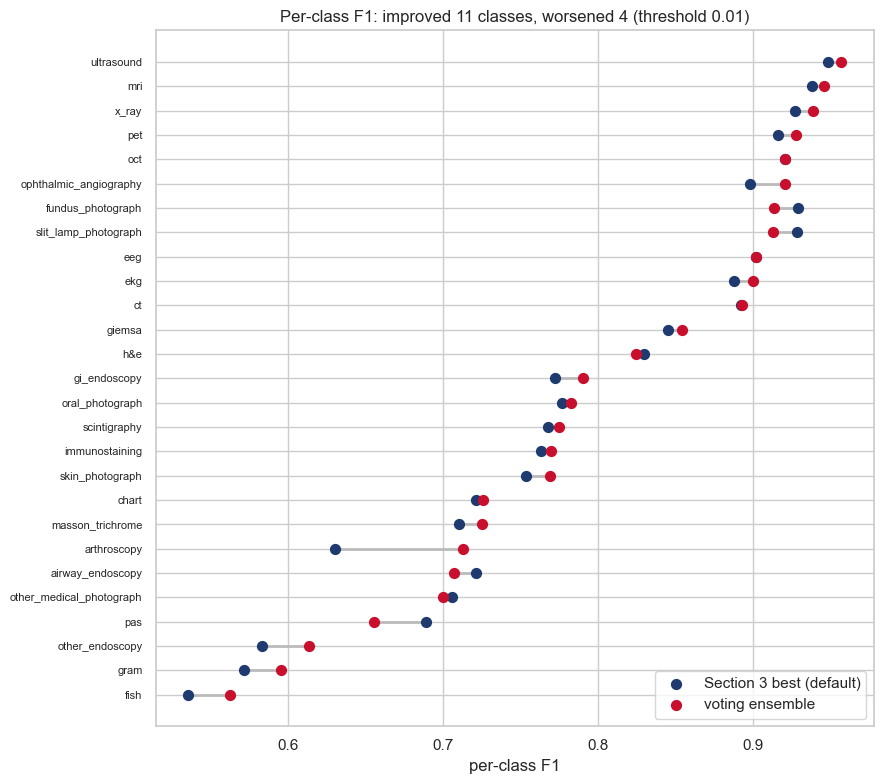

In [21]:
fa_ = f1_score(y[te], pte, labels=np.arange(K), average=None, zero_division=0); fb_ = f1_score(y[te], pe, labels=np.arange(K), average=None, zero_division=0)
de = pd.DataFrame(dict(cls=class_names, default=fa_, ensemble=fb_)).sort_values("ensemble").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 8)); ax.hlines(de.index, de.default, de.ensemble, color="#BBBBBB", lw=2)
ax.scatter(de.default, de.index, color="#1F3A6E", s=50, label="Section 3 best (default)", zorder=3); ax.scatter(de.ensemble, de.index, color="#C8102E", s=50, label="voting ensemble", zorder=3)
ax.set_yticks(de.index); ax.set_yticklabels(de.cls, fontsize=8); ax.set_xlabel("per-class F1"); ax.set_title(f"Per-class F1: improved {(de.ensemble > de.default + 0.01).sum()} classes, worsened {(de.ensemble < de.default - 0.01).sum()} (threshold 0.01)"); ax.legend(loc="lower right")
savefig("32_ensemble_per_class.png")

**How to report it:** show the before/after plot (`26_tuning_before_after.png`) and the table above. Say which change reduced the train-test gap (regularisation, tree limits, ensembling) and whether test accuracy moved. If the gap shrinks while accuracy stays the same, the model generalises better; if accuracy does not improve, the limit is the **features** (frozen ResNet50 and TF-IDF), which is why Notebook 02 is the next place to improve.

## 10. Sparse TF-IDF text models
Notebook 02 compressed the text to 200 SVD dimensions, which loses information. Here Logistic Regression uses the **full sparse TF-IDF** (3000 columns per text field). Compare with the SVD text results in Section 6.

In [22]:
import scipy.sparse as sp
Xcap = sp.load_npz(os.path.join(FEAT, "text_caption_tfidf.npz")).tocsr(); Xcase = sp.load_npz(os.path.join(FEAT, "text_case_tfidf.npz")).tocsr()
sparse_sets = {"caption TF-IDF": Xcap, "case TF-IDF": Xcase, "caption + case TF-IDF": sp.hstack([Xcap, Xcase]).tocsr()}
rows = []
for nm, Xsp in sparse_sets.items():
    for Cc in (3, 10, 30):
        cvs = []
        for f in TUNE_FOLDS:
            tr_f, va_f = tr_all[fold[tr_all] != f], tr_all[fold[tr_all] == f]; cvs.append(LogisticRegression(C=Cc, max_iter=300).fit(Xsp[tr_f], y[tr_f]).score(Xsp[va_f], y[va_f]))
        mdl = LogisticRegression(C=Cc, max_iter=300).fit(Xsp[tr_all], y[tr_all]); pp = mdl.predict(Xsp[te])
        rows.append(dict(text=nm, C=Cc, cv_acc=np.mean(cvs), train_acc=mdl.score(Xsp[tr_all], y[tr_all]), test_acc=accuracy_score(y[te], pp), test_macroF1=f1_score(y[te], pp, average="macro")))
        print(rows[-1])
sparse_res = pd.DataFrame(rows).sort_values("cv_acc", ascending=False); sparse_res.round(4).to_csv(os.path.join(RES, "sparse_tfidf_models.csv"), index=False)
svd_ref = ab.set_index("modality").test_acc.reindex(["Caption text", "Case text", "Text (both)"]).round(3).to_dict()
print("SVD-200 results from Section 6 (test acc):", svd_ref); sparse_res.round(3)

{'text': 'caption TF-IDF', 'C': 3, 'cv_acc': np.float64(0.6294245159159739), 'train_acc': 0.8137271544163414, 'test_acc': 0.6407879490150638, 'test_macroF1': 0.6352101213023266}
{'text': 'caption TF-IDF', 'C': 10, 'cv_acc': np.float64(0.6078894218377473), 'train_acc': 0.8870593560798958, 'test_acc': 0.6155272305909618, 'test_macroF1': 0.6080250007370439}
{'text': 'caption TF-IDF', 'C': 30, 'cv_acc': np.float64(0.5858009234647851), 'train_acc': 0.9362304079669552, 'test_acc': 0.59675550405562, 'test_macroF1': 0.5867346925651383}
{'text': 'case TF-IDF', 'C': 3, 'cv_acc': np.float64(0.3249955196050003), 'train_acc': 0.6456176087817574, 'test_acc': 0.3265353418308227, 'test_macroF1': 0.30057859425558237}
{'text': 'case TF-IDF', 'C': 10, 'cv_acc': np.float64(0.2928183798891681), 'train_acc': 0.7485429751598484, 'test_acc': 0.2959443800695249, 'test_macroF1': 0.27258357492654295}
{'text': 'case TF-IDF', 'C': 30, 'cv_acc': np.float64(0.26929404077260133), 'train_acc': 0.8074463871442313, 'tes

,text,C,cv_acc,train_acc,test_acc,test_macroF1
6,caption + case TF-IDF,3,0.646,0.938,0.647,0.637
7,caption + case TF-IDF,10,0.630,0.987,0.631,0.624
0,caption TF-IDF,3,0.629,0.814,0.641,0.635
8,caption + case TF-IDF,30,0.623,0.992,0.621,0.615
1,caption TF-IDF,10,0.608,0.887,0.616,0.608
2,caption TF-IDF,30,0.586,0.936,0.597,0.587
3,case TF-IDF,3,0.325,0.646,0.327,0.301
4,case TF-IDF,10,0.293,0.749,0.296,0.273
5,case TF-IDF,30,0.269,0.807,0.263,0.249


## 11. Late fusion (stacking)
Instead of one big model on all columns, **one Logistic Regression per modality block** is trained, and a small **meta-model** combines their predicted probabilities. Base-model probabilities for the training rows are **out-of-fold** (article-grouped folds), so the meta-model never sees predictions made on data the base model was trained on. Test probabilities come from base models trained on all training rows.

In [23]:
STACK_FOLDS = [1, 2] if FAST else [1, 2, 3, 4]
C_BLOCK = {"resnet": 0.01, "dinov2": 0.01, "biomedclip": 0.05, "handcrafted": 0.1, "bm_caption": 0.1, "bm_case": 0.1, "tabular": 1.0}
learners = {}
for b in [b for b in np.unique(block) if b in C_BLOCK]:
    Xb = Xs[:, block == b]; learners[b] = ((lambda C_=C_BLOCK[b]: LogisticRegression(C=C_, max_iter=300)), Xb)
learners["caption_tfidf"] = ((lambda: LogisticRegression(C=10, max_iter=300)), Xcap); learners["case_tfidf"] = ((lambda: LogisticRegression(C=3, max_iter=300)), Xcase)
def probs(make, Xm, tr_rows, ev_rows):
    m_ = make().fit(Xm[tr_rows], y[tr_rows]); P_ = np.zeros((len(ev_rows), K)); P_[:, m_.classes_] = m_.predict_proba(Xm[ev_rows]); return P_
oof_rows = tr_all[np.isin(fold[tr_all], STACK_FOLDS)]
P_oof, P_te, base_rows = {}, {}, []; t_start = time.time()
for nm, (make, Xm) in learners.items():
    t0 = time.time(); O = np.zeros((len(oof_rows), K))
    for f in STACK_FOLDS:
        tr_f = tr_all[fold[tr_all] != f]; pos = np.where(fold[oof_rows] == f)[0]; O[pos] = probs(make, Xm, tr_f, oof_rows[pos])
    P_oof[nm] = O; P_te[nm] = probs(make, Xm, tr_all, te)
    base_rows.append(dict(block=nm, oof_acc=accuracy_score(y[oof_rows], O.argmax(1)), test_acc=accuracy_score(y[te], P_te[nm].argmax(1)), seconds=time.time() - t0)); print(base_rows[-1])
print("base learners: %.1f min" % ((time.time() - t_start) / 60)); pd.DataFrame(base_rows).round(3)

{'block': np.str_('biomedclip'), 'oof_acc': 0.7659141062637922, 'test_acc': 0.7768250289687137, 'seconds': 39.83885741233826}
{'block': np.str_('bm_caption'), 'oof_acc': 0.683698296836983, 'test_acc': 0.687369640787949, 'seconds': 26.89961075782776}
{'block': np.str_('bm_case'), 'oof_acc': 0.3211112997227409, 'test_acc': 0.327694090382387, 'seconds': 33.74677491188049}
{'block': np.str_('dinov2'), 'oof_acc': 0.7603689243478753, 'test_acc': 0.774739281575898, 'seconds': 147.2616424560547}
{'block': np.str_('handcrafted'), 'oof_acc': 0.4650031120918916, 'test_acc': 0.4880648899188876, 'seconds': 23.218045711517334}
{'block': np.str_('resnet'), 'oof_acc': 0.7350761047926215, 'test_acc': 0.7524913093858633, 'seconds': 94.33469581604004}
{'block': np.str_('tabular'), 'oof_acc': 0.07123861257285125, 'test_acc': 0.07439165701042874, 'seconds': 2.133411169052124}
{'block': 'caption_tfidf', 'oof_acc': 0.6036892434787529, 'test_acc': 0.6155272305909618, 'seconds': 22.29067850112915}
{'block': 'c

,block,oof_acc,test_acc,seconds
0,biomedclip,0.766,0.777,39.839
1,bm_caption,0.684,0.687,26.900
2,bm_case,0.321,0.328,33.747
3,dinov2,0.760,0.775,147.262
4,handcrafted,0.465,0.488,23.218
5,resnet,0.735,0.752,94.335
6,tabular,0.071,0.074,2.133
7,caption_tfidf,0.604,0.616,22.291
8,case_tfidf,0.330,0.327,44.808


In [24]:
names_l = list(learners); logp = lambda d, i=None: np.hstack([np.log(d[n] + 1e-4) for n in names_l])
Z_oof, Z_te = logp(P_oof), logp(P_te); y_oof = y[oof_rows]; f_oof = fold[oof_rows]
best_meta, best_cv = None, -1
for Cm in (0.01, 0.03, 0.1, 0.3, 1.0):
    cv_ = [LogisticRegression(C=Cm, max_iter=500).fit(Z_oof[f_oof != f], y_oof[f_oof != f]).score(Z_oof[f_oof == f], y_oof[f_oof == f]) for f in STACK_FOLDS]
    print(f"meta C={Cm}: CV={np.mean(cv_):.4f}")
    if np.mean(cv_) > best_cv: best_meta, best_cv = Cm, np.mean(cv_)
meta = LogisticRegression(C=best_meta, max_iter=500).fit(Z_oof, y_oof); Pm = meta.predict_proba(Z_te); pm = Pm.argmax(1)
stack = dict(cv=best_cv, test=accuracy_score(y[te], pm), f1=f1_score(y[te], pm, average="macro"), train=meta.score(Z_oof, y_oof))
try: stack["auc"] = roc_auc_score(y[te], Pm, multi_class="ovr", average="macro", labels=np.arange(K))
except Exception: stack["auc"] = np.nan
print("STACKING:", {k: round(v, 4) for k, v in stack.items()})
pd.DataFrame(base_rows).assign(role="base").round(3).to_csv(os.path.join(RES, "stacking_base_learners.csv"), index=False)

meta C=0.01: CV=0.7914
meta C=0.03: CV=0.7790
meta C=0.1: CV=0.7620
meta C=0.3: CV=0.7524
meta C=1.0: CV=0.7421
STACKING: {'cv': np.float64(0.7914), 'test': 0.8063, 'f1': 0.7965, 'train': 0.8441, 'auc': 0.9878}


### Visual: which modality does the stacking model trust?
Left: out-of-fold and test accuracy of each base learner. Right: share of the meta-model's absolute weights given to each base learner.

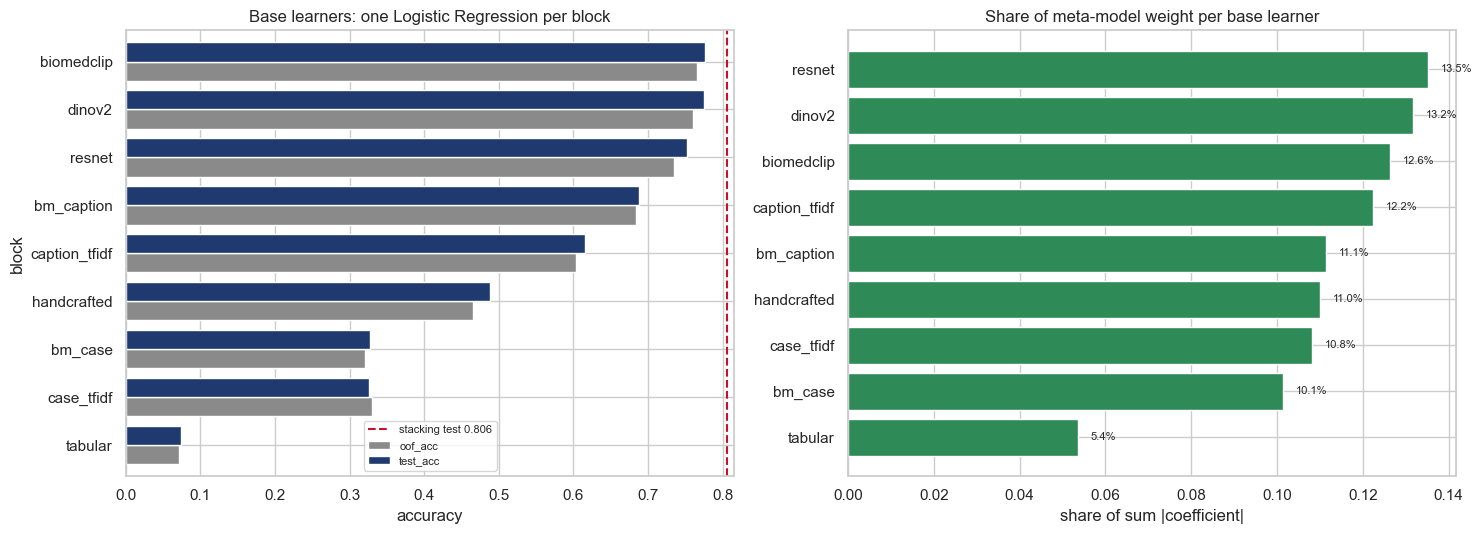

In [25]:
bl_ = pd.DataFrame(base_rows).set_index("block")
W_ = np.abs(meta.coef_); share = pd.Series({n_: W_[:, i_ * K:(i_ + 1) * K].sum() / W_.sum() for i_, n_ in enumerate(names_l)}).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
bl_.sort_values("test_acc")[["oof_acc", "test_acc"]].plot.barh(ax=ax[0], width=0.8, color=["#8A8A8A", "#1F3A6E"]); ax[0].axvline(stack["test"], ls="--", c="#C8102E", label=f"stacking test {stack['test']:.3f}"); ax[0].legend(fontsize=8); ax[0].set_title("Base learners: one Logistic Regression per block"); ax[0].set_xlabel("accuracy")
ax[1].barh(share.index, share.values, color="#2E8B57"); ax[1].set_title("Share of meta-model weight per base learner"); ax[1].set_xlabel("share of sum |coefficient|")
for i_, v_ in enumerate(share.values): ax[1].text(v_ + 0.003, i_, f"{v_:.1%}", va="center", fontsize=8)
savefig("33_stacking_blocks.png")

## 12. Hierarchical model: image type first, then subtype
A type classifier (7 classes) is trained on all rows, then one subtype classifier per type (trained only on rows of that type). The final subtype probability is **P(type) x P(subtype | type)**. This focuses each subtype model on a smaller, more homogeneous problem (for example gi_endoscopy vs airway_endoscopy inside "endoscopy").

In [26]:
if TARGET != "subtype": print("Hierarchical model only applies to TARGET = 'subtype'")
else:
    t0 = time.time(); Ch = tuned[("All features", "LogReg")]["params"]["C"] if ("All features", "LogReg") in tuned else 0.003
    sub2type = pd.Series(y_type[tr_all], index=y_sub[tr_all]).groupby(level=0).first().to_dict()
    scH = Xs[tr_all]; scT = Xs[te]
    mt = LogisticRegression(C=Ch, max_iter=300).fit(scH, y_type[tr_all]); Pt = np.zeros((len(te), y_type.max() + 1)); Pt[:, mt.classes_] = mt.predict_proba(scT)
    Ph = np.zeros((len(te), K))
    for t in np.unique(y_type[tr_all]):
        subs = sorted(s_ for s_, tt in sub2type.items() if tt == t); rows_t = np.where(y_type[tr_all] == t)[0]
        if len(subs) == 1: Ph[:, subs[0]] = Pt[:, t]; continue
        mm = LogisticRegression(C=Ch, max_iter=300).fit(scH[rows_t], y[tr_all][rows_t]); Pc = mm.predict_proba(scT)
        for j, cls in enumerate(mm.classes_): Ph[:, cls] = Pt[:, t] * Pc[:, j]
    ph = Ph.argmax(1); hier = dict(test=accuracy_score(y[te], ph), f1=f1_score(y[te], ph, average="macro"), type_acc=accuracy_score(y_type[te], mt.predict(scT)))
    try: hier["auc"] = roc_auc_score(y[te], Ph / Ph.sum(1, keepdims=True), multi_class="ovr", average="macro", labels=np.arange(K))
    except Exception: hier["auc"] = np.nan
    flat_ref = tuned[("All features", "LogReg")]["test"] if ("All features", "LogReg") in tuned else np.nan
    print("HIERARCHICAL:", {k: round(v, 4) for k, v in hier.items()}, "| flat LogReg (same C):", round(flat_ref, 4), f"| {time.time()-t0:.0f}s")

HIERARCHICAL: {'test': 0.8155, 'f1': 0.8021, 'type_acc': 0.9196, 'auc': 0.988} | flat LogReg (same C): 0.8146 | 112s


### Visual: image-type confusion of the hierarchical model (first stage)
The first stage decides the image type (7 classes), the second stage picks the subtype inside it. Errors made here cannot be fixed later.

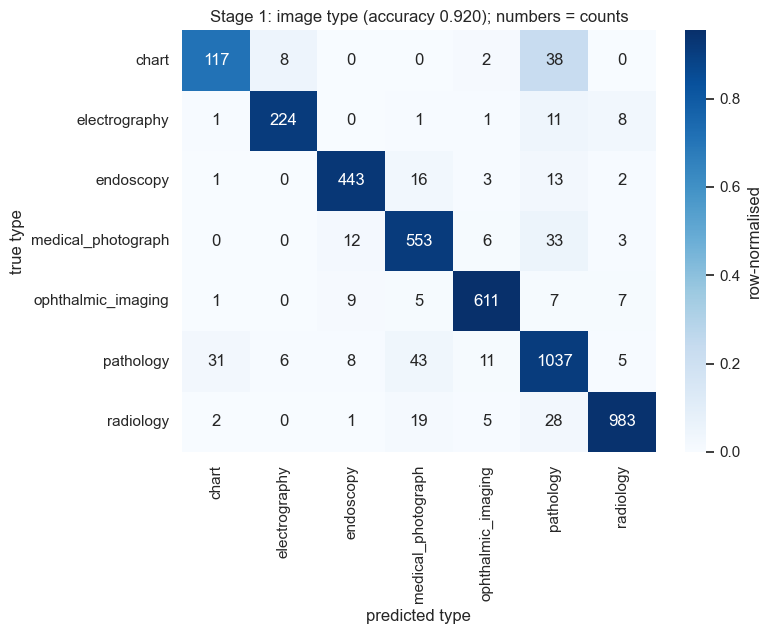

In [27]:
if TARGET == "subtype":
    tn_ = np.array(classes["image_type"]); pt_ = mt.predict(scT); ct_ = confusion_matrix(y_type[te], pt_, labels=np.arange(len(tn_))); ctn_ = ct_ / ct_.sum(1, keepdims=True).clip(1)
    plt.figure(figsize=(8, 6.5)); sns.heatmap(ctn_, annot=ct_, fmt="d", cmap="Blues", xticklabels=tn_, yticklabels=tn_, cbar_kws={"label": "row-normalised"}); plt.xlabel("predicted type"); plt.ylabel("true type"); plt.title(f"Stage 1: image type (accuracy {hier['type_acc']:.3f}); numbers = counts")
    savefig("34_hierarchical_type_confusion.png")

## 13. Error analysis: look at the misclassified images

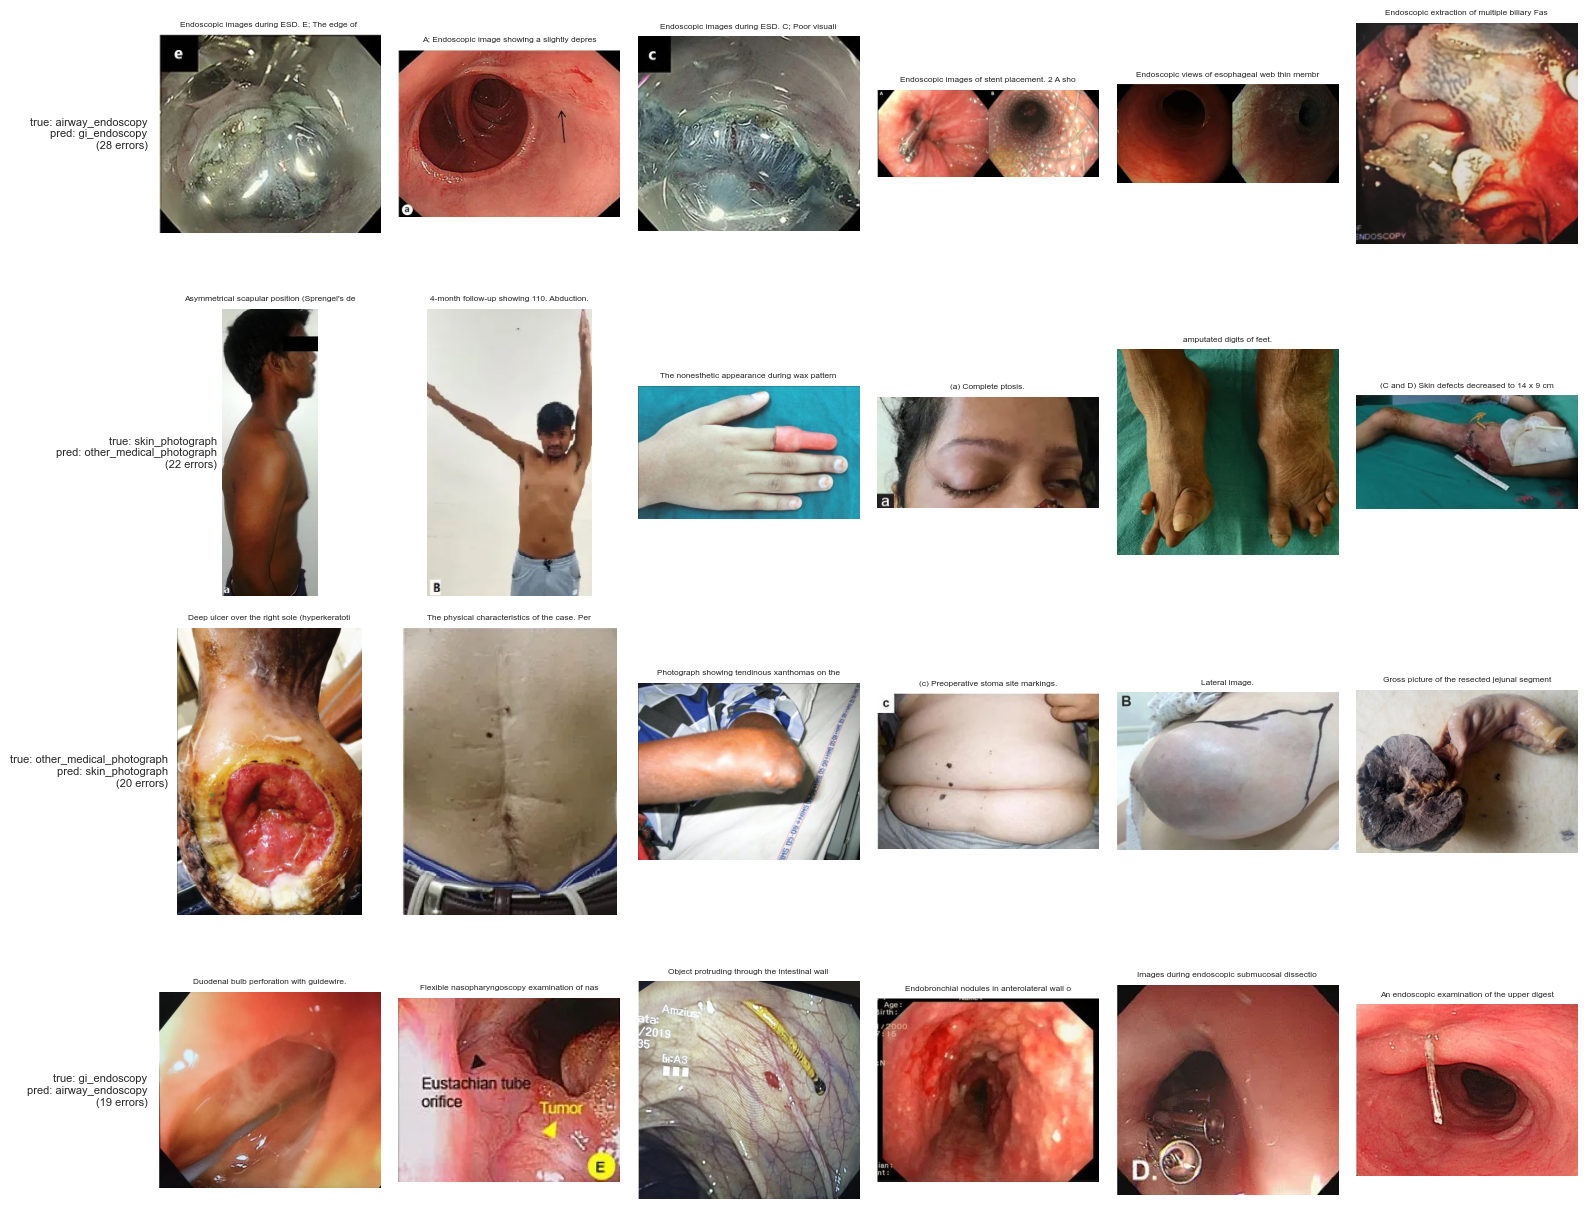

What to look for: multi-panel figures, charts or diagrams labelled as photos/slides, very small images, and captions that describe a different modality than the label.


In [28]:
pte_best = m.predict(B); cm2 = confusion_matrix(y[te], pte_best, labels=np.arange(K))
pairs = sorted([(cm2[i, j], i, j) for i in range(K) for j in range(K) if i != j], reverse=True)[:4]
caps = dict(zip(*pd.read_parquet(os.path.join(DATA_DIR, "outputs", "subset.parquet"), columns=["file", "caption"]).T.values)) if os.path.exists(os.path.join(DATA_DIR, "outputs", "subset.parquet")) else {}
from PIL import Image
files = idx.file.values; shown = 0
fig, axes = plt.subplots(len(pairs), 6, figsize=(16, 3.2 * len(pairs)))
for r_, (cnt, i, j) in enumerate(pairs):
    sel_ = te[(y[te] == i) & (pte_best == j)][:6]
    for c_ in range(6):
        a = axes[r_, c_]; a.axis("off")
        if c_ < len(sel_):
            f_ = files[sel_[c_]]; p_ = os.path.join(DATA_DIR, f_[:4], f_[:5], f_)
            if os.path.exists(p_): a.imshow(Image.open(p_).convert("RGB")); shown += 1
            a.set_title(str(caps.get(f_, ""))[:45], fontsize=6)
    axes[r_, 0].text(-0.05, 0.5, f"true: {class_names[i]}\npred: {class_names[j]}\n({cnt} errors)", transform=axes[r_, 0].transAxes, ha="right", va="center", fontsize=8)
if shown: savefig("27_error_analysis_images.png")
else: print("image files not found next to the notebook -> skipped plot")
print("What to look for: multi-panel figures, charts or diagrams labelled as photos/slides, very small images, and captions that describe a different modality than the label.")

## 14. Final comparison of all approaches

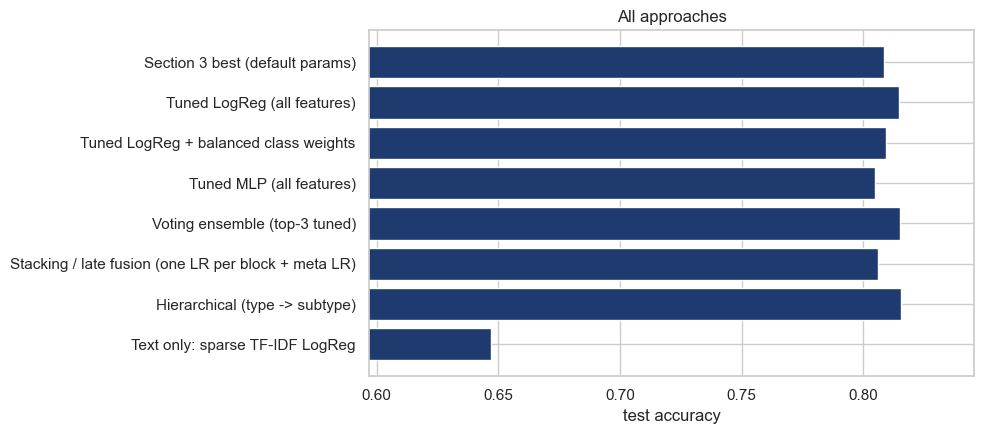

,approach,features / models,"cv_acc (folds used differ, see text)",test_acc,test_macroF1
0,Section 3 best (default params),All features + MLP,0.795,0.809,0.795
1,Tuned LogReg (all features),All features + LogReg,0.809,0.815,0.801
2,Tuned LogReg + balanced class weights,All features + LogRegBal,0.806,0.810,0.796
3,Tuned MLP (all features),All features + MLP,0.802,0.805,0.793
4,Voting ensemble (top-3 tuned),All features/LogReg + All features/LogRegBal +...,0.810,0.815,0.804
5,Stacking / late fusion (one LR per block + met...,9 base learners,0.791,0.806,0.796
6,Hierarchical (type -> subtype),"LogReg, all features",NaN,0.816,0.802
7,Text only: sparse TF-IDF LogReg,caption + case TF-IDF,0.646,0.647,0.637


In [29]:
fin = [["Section 3 best (default params)", f"{grid.iloc[0].features} + {grid.iloc[0].model}", grid.iloc[0].cv_acc, grid.iloc[0].test_acc, grid.iloc[0].test_macroF1]]
for k_, lab_ in [(("All features", "LogReg"), "Tuned LogReg (all features)"), (("All features", "LogRegBal"), "Tuned LogReg + balanced class weights"), (("All features", "MLP"), "Tuned MLP (all features)")]:
    if k_ in tuned: fin.append([lab_, f"{k_[0]} + {k_[1]}", tuned[k_]["cv"], tuned[k_]["test"], tuned[k_]["f1"]])
fin.append(["Voting ensemble (top-3 tuned)", " + ".join(f"{a}/{b}" for a, b in members), ens["cv"], ens["test"], ens["f1"]])
fin.append(["Stacking / late fusion (one LR per block + meta LR)", f"{len(learners)} base learners", stack["cv"], stack["test"], stack["f1"]])
if TARGET == "subtype": fin.append(["Hierarchical (type -> subtype)", "LogReg, all features", np.nan, hier["test"], hier["f1"]])
best_sparse = sparse_res.iloc[0]; fin.append(["Text only: sparse TF-IDF LogReg", best_sparse.text, best_sparse.cv_acc, best_sparse.test_acc, best_sparse.test_macroF1])
final_all = pd.DataFrame(fin, columns=["approach", "features / models", "cv_acc (folds used differ, see text)", "test_acc", "test_macroF1"]); final_all.round(4).to_csv(os.path.join(RES, "final_comparison_all.csv"), index=False)
plt.figure(figsize=(10, 4.5)); r_ = final_all.iloc[::-1]; plt.barh(r_.approach, r_.test_acc, color="#1F3A6E"); plt.xlim(max(0, r_.test_acc.min() - 0.05), min(1, r_.test_acc.max() + 0.03)); plt.xlabel("test accuracy"); plt.title("All approaches"); savefig("28_final_comparison.png")
final_all.round(3)

### Visual: accuracy and macro-F1 of every approach

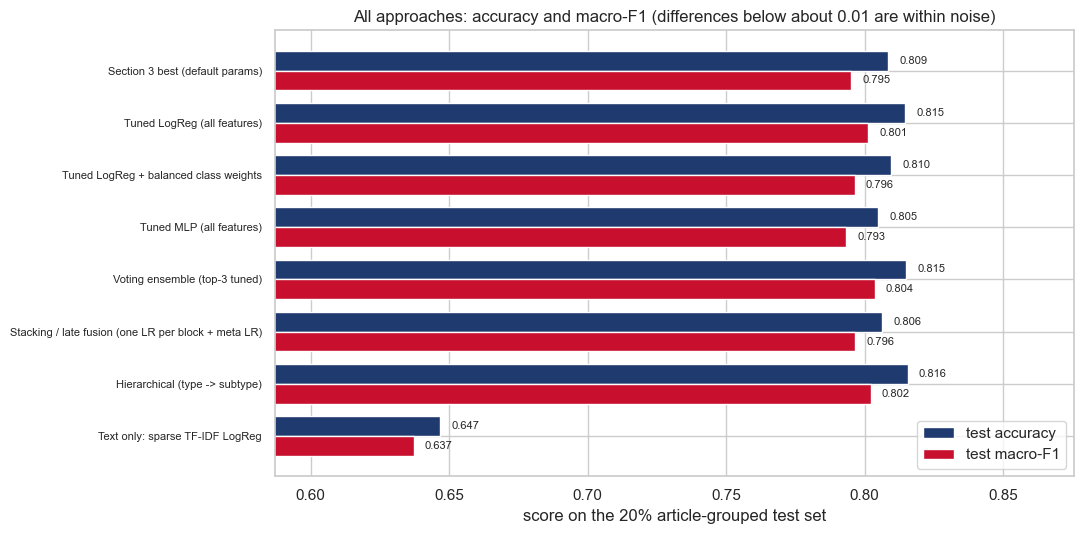

In [30]:
r_ = final_all.iloc[::-1].reset_index(drop=True); yy = np.arange(len(r_)); h_ = 0.38
fig, ax = plt.subplots(figsize=(11, 5.5)); ax.barh(yy + h_ / 2, r_.test_acc, h_, color="#1F3A6E", label="test accuracy"); ax.barh(yy - h_ / 2, r_.test_macroF1, h_, color="#C8102E", label="test macro-F1")
for y_, a_, f_ in zip(yy, r_.test_acc, r_.test_macroF1): ax.text(a_ + 0.004, y_ + h_ / 2, f"{a_:.3f}", va="center", fontsize=8); ax.text(f_ + 0.004, y_ - h_ / 2, f"{f_:.3f}", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(r_.approach, fontsize=8); ax.set_xlim(max(0, min(r_.test_acc.min(), r_.test_macroF1.min()) - 0.05), min(1.02, r_.test_acc.max() + 0.06)); ax.set_xlabel("score on the 20% article-grouped test set")
ax.set_title("All approaches: accuracy and macro-F1 (differences below about 0.01 are within noise)"); ax.legend(loc="lower right"); savefig("35_final_accuracy_f1.png")